# Sieci neuronowe – lista 4: PyTorch

**Część 1.** Sieć z listy 3 (własna implementacja w numpy, forward/backward) odtworzona w PyTorchu.
Startuję od wersji przepisanej prosto z tutorialu i **krok po kroku usuwam różnice**, aż PyTorch daje to samo co lista 3.
Podobieństwo sprawdzam na 4 poziomach:

| poziom | co porównuję |
|---|---|
| 1. pojedyncze operacje | koszt, pochodna kosztu, ReLU, warstwa Linear, `zero_grad` |
| 2. jeden krok uczenia | logity, koszt, gradienty i wagi po jednym kroku SGD / ADAM |
| 3. wagi krok po kroku | obie implementacje uczą się obok siebie, po każdym kroku porównuję wszystkie wagi |
| 4. eksperymenty z listy 3 | wszystkie konfiguracje z listy 3: krzywe kosztu, F1, predykcje, wagi końcowe |

**Część 2.** Klasyfikacja CIFAR10 większą siecią: baseline do kolejnego zadania.

# CZĘŚĆ 1 – replikacja sieci z listy 3 w PyTorchu

## Konfiguracja

Kod z listy 3 (`lab3/lab3.py`, `lab3/lab3_cz2.py`) importuję bez zmian, więc numpy liczy dokładnie tym samym kodem co na liście 3.
Wszystkie obliczenia na CPU, na 1 wątku na przebieg (jak w lab3), z kilkoma przebiegami równolegle (`joblib`).

In [1]:
import os, sys, time, inspect
for var in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[var] = "1"                       # 1 wątek na przebieg, jak w lab3
LAB4 = os.getcwd()
LAB3 = os.path.abspath(os.path.join(LAB4, "..", "lab3"))
sys.path.insert(0, LAB3)
os.environ["PYTHONPATH"] = LAB3                 # żeby procesy joblib też widziały lab3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Sampler, BatchSampler, RandomSampler
from joblib import Parallel, delayed
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

import lab3, lab3_cz2                           # oryginalny kod listy 3 (numpy)
os.chdir(LAB4)                                  # import lab3 zmienia katalog roboczy

torch.set_num_threads(1)
N_JOBS = max(1, (os.cpu_count() or 2) // 2)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"numpy {np.__version__}, torch {torch.__version__}, urządzenie: {device}, procesy równoległe: {N_JOBS}")

numpy 2.2.4, torch 2.15.0+cpu, urządzenie: cpu, procesy równoległe: 8


## Dane (lista 1–3)

Ten sam podział co w liście 2 i 3: target binarny (0 = zdrowy, 1 = chory), braki uzupełnione dominantą, one-hot (28 cech),
standaryzacja cech liczbowych, 242 pacjentów treningowych i 61 testowych. Biorę je wprost z `lab3.py`.

In [2]:
X_train, X_test, y_train, y_test = lab3.X_train, lab3.X_test, lab3.y_train, lab3.y_test
X_train_raw, X_test_raw = lab3.X_train_raw, lab3.X_test_raw
n_features = lab3.n_features
p1 = y_train.mean()
L_prior = -(p1 * np.log(p1) + (1 - p1) * np.log(1 - p1))   # koszt modelu, który zawsze mówi p = odsetek chorych
print(f"X_train {X_train.shape}, X_test {X_test.shape}, chorzy: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
print(f"koszt 'zgadywania' (plateau): {L_prior:.4f}")

X_train (242, 28), X_test (61, 28), chorzy: train 0.459, test 0.459
koszt 'zgadywania' (plateau): 0.6897


## Implementacja z listy 3 (przypomnienie)

Każdy moduł ma ręcznie napisane `forward` i `backward`. To jest kod, który PyTorch ma zastąpić:

In [3]:
for obj in [lab3.Linear, lab3.ReLU, lab3.SigmoidBCELoss, lab3.MLP.backward, lab3.MLP.step]:
    print(inspect.getsource(obj))

class Linear:
    # y = W x + b
    def __init__(self, n_in, n_out, rng, std=STD_INIT):
        self.W = rng.normal(0, std, (n_out, n_in))
        self.b = rng.normal(0, std, (1, n_out))

    def forward(self, x):
        self.x = x
        return x @ self.W.T + self.b

    def backward(self, d):
        self.dW = d.T @ self.x              
        self.db = d.sum(axis=0, keepdims=True)
        return d @ self.W                   

class ReLU:
    def forward(self, x):
        self.x = x
        return np.maximum(0, x)

    def backward(self, d):
        return d * (self.x > 0)             

class SigmoidBCELoss:
    def forward(self, z, y):
        self.p = sigmoid(z)
        self.y = y.reshape(-1, 1)
        return np.mean(np.maximum(z, 0) - z * self.y + np.log1p(np.exp(-np.abs(z))))

    def backward(self):
        return (self.p - self.y) / len(self.y)

    def backward(self, d):
        for layer in reversed(self.layers): 
            d = layer.backward(d)

    def step(self, lr):

## Ta sama sieć w PyTorchu

Jak w tutorialu: klasa dziedziczy po `nn.Module` i ma **tylko `forward`**. Warstwy biorę z `torch.nn`.
Sigmoid nie jest w sieci, tylko w funkcji kosztu (`nn.BCEWithLogitsLoss`), tak samo jak `SigmoidBCELoss` w liście 3.

In [4]:
class NeuralNetwork(nn.Module):
    # [Linear -> ReLU] x liczba warstw ukrytych -> Linear (logit)
    def __init__(self, sizes):
        super().__init__()
        layers = []
        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:
                layers.append(nn.ReLU())
        self.linear_relu_stack = nn.Sequential(*layers)

    def forward(self, x):
        return self.linear_relu_stack(x)

    def linear_layers(self):
        return [m for m in self.linear_relu_stack if isinstance(m, nn.Linear)]

    def predict_proba(self, X):
        dtype = self.linear_layers()[0].weight.dtype
        with torch.no_grad():
            return torch.sigmoid(self(torch.as_tensor(np.asarray(X), dtype=dtype))).numpy().ravel()


def to_tensor(a, dtype=torch.float64):
    return torch.as_tensor(np.asarray(a), dtype=dtype)


def np_linear(np_model):
    return [l for l in np_model.layers if isinstance(l, lab3.Linear)]


def copy_weights(np_model, model):
    # wagi z modelu numpy do torcha: W ma ten sam kształt (out, in), b: (1, out) -> (out,)
    with torch.no_grad():
        for nl, l in zip(np_linear(np_model), model.linear_layers()):
            l.weight.copy_(torch.as_tensor(nl.W))
            l.bias.copy_(torch.as_tensor(nl.b).ravel())


def rel_diff(a, b):
    # max |a - b| / max(1, |b|): dla małych liczb różnica bezwzględna, dla dużych (koszt 1e30) względna.
    # Pozycje, gdzie obie wartości to inf/NaN, pomijam; inf/NaN tylko w jednej wersji -> inf
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if np.any(np.isfinite(a) != np.isfinite(b)):
        return np.inf
    ok = np.isfinite(a)
    if not ok.any():
        return 0.0
    return float(np.max(np.abs(a[ok] - b[ok]) / np.maximum(1.0, np.abs(b[ok]))))


def weights_diff(model, np_model):
    with np.errstate(all="ignore"):
        return max(max(rel_diff(l.weight.detach().double().numpy(), nl.W),
                       rel_diff(l.bias.detach().double().numpy(), nl.b.ravel()))
                   for l, nl in zip(model.linear_layers(), np_linear(np_model)))


model = NeuralNetwork([n_features, 4, 1]).double()
print(model)

NeuralNetwork(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=28, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=1, bias=True)
  )
)


### Graf obliczeń

Każda operacja na tensorze zapamiętuje w wyniku (`.grad_fn`), z czego powstał. Przechodząc od kosztu w tył, dostaję
dokładnie listę modułów z listy 3 czytaną od końca, czyli to, co robiło `MLP.backward`:

In [5]:
names = {id(p): n for n, p in model.named_parameters()}
loss = nn.BCEWithLogitsLoss()(model(to_tensor(X_train[:5])), to_tensor(y_train[:5]).reshape(-1, 1))

def show_graph(fn, depth=0):
    if fn is None:
        return
    label = type(fn).__name__
    if hasattr(fn, "variable"):
        label += f"   ->  {names[id(fn.variable)]} {tuple(fn.variable.shape)}"
    print("    " * depth + label)
    for nxt, _ in fn.next_functions:
        show_graph(nxt, depth + 1)

show_graph(loss.grad_fn)

BinaryCrossEntropyWithLogitsBackward0
    AddmmBackward0
        AccumulateGrad   ->  linear_relu_stack.2.bias (1,)
        ReluBackward0
            AddmmBackward0
                AccumulateGrad   ->  linear_relu_stack.0.bias (4,)
                TBackward0
                    AccumulateGrad   ->  linear_relu_stack.0.weight (4, 28)
        TBackward0
            AccumulateGrad   ->  linear_relu_stack.2.weight (1, 4)


`AddmmBackward0` to warstwa Linear (`x @ W.T + b`), `ReluBackward0` to ReLU, a `AccumulateGrad` to liść grafu, czyli parametr.
Tam `loss.backward()` zapisuje gradient (`parametr.grad`), tak jak w liście 3 robiło `self.dW = ...`.

Pętla uczenia z tutorialu i jej odpowiednik z listy 3:

| lista 3 (numpy) | PyTorch |
|---|---|
| `loss_fn.forward(model.forward(X), y)` | `loss = loss_fn(model(X), y)` |
| `model.backward(loss_fn.backward())` | `loss.backward()` |
| `model.step(lr)` | `optimizer.step()` |
| – (gradient nadpisywany: `self.dW = ...`) | `optimizer.zero_grad()` (gradient dodawany: `+=`) |

## Różnice implementacyjne

Lista rzeczy, które mogą sprawić, że PyTorch da inny wynik niż lista 3. Każdą sprawdzam niżej.

| # | różnica | lista 3 (numpy) | domyślnie w PyTorchu (tutorial) | jak usuwam | gdzie sprawdzam |
|---|---|---|---|---|---|
| 1 | rozkład wag początkowych | N(0, 0.01) dla W i b (cz. 1), N(0, σ) i b = 0 (cz. 2) | `nn.Linear`: jednostajny ±1/√n_in | `nn.init.normal_` | eliminacja, etap S1 |
| 2 | wartości wag początkowych | generator `np.random.default_rng` | generator torcha | kopiuję wagi z modelu numpy | eliminacja, etap S2 |
| 3 | precyzja | float64 | float32 | `.double()` | poziom 2, etap S3, poziom 3 |
| 4 | sigmoid + koszt | jeden moduł `SigmoidBCELoss`, gradient p − y | tutorialowe `Sigmoid` + `BCELoss` | `BCEWithLogitsLoss` | poziom 1, etap S4 |
| 5 | kolejność przykładów w paczkach | `default_rng(seed + 1000).permutation` | `DataLoader(shuffle=True)` | własny `Sampler` z permutacją numpy | etap S5 |
| 6 | gradient | nadpisywany | dodawany (`+=`) | `zero_grad()` po każdym kroku | poziom 1 |
| 7 | ReLU w zerze i przy gradiencie inf | pochodna 0 dla x ≤ 0, ale `inf · 0 = nan` | pochodna 0, gradient 0 | – (sprawdzam, czy ma znaczenie) | poziom 1, poziom 4 |
| 8 | odchylenie std (statystyki warstw w cz. 2) | `ndarray.std()` dzieli przez N | `tensor.std()` dzieli przez N − 1 | `std(correction=0)` | poziom 1 |
| 9 | optymalizatory | własne GD i ADAM | `torch.optim.SGD`, `torch.optim.Adam` | te same parametry; wzory równoważne, inna kolejność działań | poziom 2, poziom 3 |
| 10 | biblioteki liczące (BLAS) | OpenBLAS | biblioteki torcha | nie da się usunąć: różnice rzędu 1e-16 | poziom 3, kontrola |

## Poziom 1 – pojedyncze operacje

**(a) Koszt i jego pochodna dla logitów.** Porównuję `SigmoidBCELoss` z listy 3 z dwiema wersjami w PyTorchu:
`BCEWithLogitsLoss` oraz tutorialowe `Sigmoid` + `BCELoss`. Logity: 1000 losowych z N(0, 3) i 4 skrajne (±40, ±800).

In [6]:
rng = np.random.default_rng(0)
z = np.concatenate([rng.normal(0, 3, 1000), [-800, -40, 40, 800]]).reshape(-1, 1)
t = rng.integers(0, 2, len(z)).astype(float)
t[-4:] = [1, 1, 0, 0]                          # skrajne logity z ZŁĄ odpowiedzią: sieć jest pewna i się myli

ref = lab3.SigmoidBCELoss()
L_np = ref.forward(z, t)
g_np = ref.backward().ravel()

rows = []
for name, fn in [("BCEWithLogitsLoss", lambda zz, tt: nn.BCEWithLogitsLoss()(zz, tt)),
                 ("Sigmoid + BCELoss", lambda zz, tt: nn.BCELoss()(torch.sigmoid(zz), tt))]:
    zt = to_tensor(z).requires_grad_()
    L_t = fn(zt, to_tensor(t).reshape(-1, 1))
    L_t.backward()
    g_t = zt.grad.numpy().ravel()
    rows.append({"wersja PyTorch": name, "koszt numpy": L_np, "koszt torch": L_t.item(),
                 "max |Δ dL/dz| (zwykłe logity)": np.abs(g_t[:-4] - g_np[:-4]).max(),
                 "dL/dz dla z = -800, 800 (numpy)": np.round(g_np[[-4, -1]] * len(z), 3),
                 "dL/dz dla z = -800, 800 (torch)": np.round(g_t[[-4, -1]] * len(z), 3)})
pd.DataFrame(rows).set_index("wersja PyTorch")

,koszt numpy,koszt torch,max |Δ dL/dz| (zwykłe logity),"dL/dz dla z = -800, 800 (numpy)","dL/dz dla z = -800, 800 (torch)"
wersja PyTorch,,,,,
BCEWithLogitsLoss,3.099728,3.099728,2.168404e-19,"[-1.0, 1.0]","[-1.0, 1.0]"
Sigmoid + BCELoss,3.099728,1.765067,2.168404e-19,"[-1.0, 1.0]","[-0.0, 0.0]"


- `BCEWithLogitsLoss` daje ten sam koszt i tę samą pochodną co lista 3 (różnica ~1e-19).
- `Sigmoid` + `BCELoss` jest inne w dwóch miejscach:
  - przy z = ±800 sigmoid w float64 to dokładnie 0 albo 1. `BCELoss` obcina log(0) do −100, więc **koszt jest zaniżony**;
  - **gradient znika**. Pochodna sigmoidu p(1 − p) = 0, więc dL/dz = 0, choć sieć myli się maksymalnie.
    W liście 3 (p − y) daje ±1.

  To się liczy przy dużych wagach (inicjalizacja N(0, 1) w części 2 listy 3).

**(b) ReLU, warstwa Linear, `zero_grad`, odchylenie std.**

In [7]:
# ReLU: pochodna w zerze i co się dzieje, gdy z góry przychodzi gradient inf
x = np.array([[-1.0, 0.0, 2.0]])
relu = lab3.ReLU(); relu.forward(x)
with np.errstate(all="ignore"):
    d_np = [relu.backward(np.ones_like(x)).ravel(), relu.backward(np.full_like(x, np.inf)).ravel()]
d_t = []
for g in [1.0, np.inf]:
    xt = to_tensor(x).requires_grad_()
    torch.relu(xt).backward(torch.full_like(xt, g))
    d_t.append(xt.grad.numpy().ravel())
display(pd.DataFrame({"x": x.ravel(), "dReLU numpy (gradient 1)": d_np[0], "dReLU torch (gradient 1)": d_t[0],
                      "numpy (gradient inf)": d_np[1], "torch (gradient inf)": d_t[1]}))

# Linear: forward i backward z listy 3 vs nn.Linear + autograd, te same wagi
rng = np.random.default_rng(1)
lin = lab3.Linear(n_features, 6, rng, std=0.5)
xb, d = rng.normal(size=(10, n_features)), rng.normal(size=(10, 6))
y_np, dx_np = lin.forward(xb), None
dx_np = lin.backward(d)
tl = nn.Linear(n_features, 6).double()
with torch.no_grad():
    tl.weight.copy_(torch.as_tensor(lin.W)); tl.bias.copy_(torch.as_tensor(lin.b).ravel())
xt = to_tensor(xb).requires_grad_()
yt = tl(xt)
yt.backward(to_tensor(d))
print(f"Linear: max |Δ wyjście| = {np.abs(yt.detach().numpy() - y_np).max():.1e}, "
      f"|Δ dW| = {np.abs(tl.weight.grad.numpy() - lin.dW).max():.1e}, "
      f"|Δ db| = {np.abs(tl.bias.grad.numpy() - lin.db.ravel()).max():.1e}, "
      f"|Δ dx| = {np.abs(xt.grad.numpy() - dx_np).max():.1e}")

# zero_grad: backward dodaje do .grad
m = NeuralNetwork([n_features, 4, 1]).double()
W = m.linear_layers()[0].weight
for i in range(2):
    nn.BCEWithLogitsLoss()(m(to_tensor(X_train)), to_tensor(y_train).reshape(-1, 1)).backward()
    print(f"backward nr {i + 1} bez zero_grad: |W.grad| = {W.grad.norm():.6f}")
m.zero_grad()
print(f"po zero_grad(): W.grad = {W.grad}")

# odchylenie std: numpy dzieli przez N, torch domyślnie przez N - 1
v = np.random.default_rng(2).normal(size=242)
print(f"std: numpy {v.std():.6f}, torch std() {to_tensor(v).std():.6f}, torch std(correction=0) {to_tensor(v).std(correction=0):.6f}")

,x,dReLU numpy (gradient 1),dReLU torch (gradient 1),numpy (gradient inf),torch (gradient inf)
0,-1.0,0.0,0.0,NaN,0.0
1,0.0,0.0,0.0,NaN,0.0
2,2.0,1.0,1.0,inf,inf


Linear: max |Δ wyjście| = 0.0e+00, |Δ dW| = 8.9e-16, |Δ db| = 8.9e-16, |Δ dx| = 4.4e-16
backward nr 1 bez zero_grad: |W.grad| = 0.200416
backward nr 2 bez zero_grad: |W.grad| = 0.400832
po zero_grad(): W.grad = None
std: numpy 1.006049, torch std() 1.008134, torch std(correction=0) 1.006049


- **ReLU** ma w zerze tę samą pochodną (0). Różni się tylko przy gradiencie `inf`: numpy liczy `inf · 0 = nan`, a torch daje 0.
  Może to mieć znaczenie tylko w przebiegach, które się rozbiegają (N(0, 10)). Na poziomie 4 sprawdzam, czy zmienia wynik.
- **Linear**: wyjście i wszystkie trzy gradienty (dW, db, dx) są identyczne z autogradem (różnice ~1e-16 lub 0).
- **`zero_grad`**: bez zerowania gradient po drugim `backward` jest dokładnie 2 razy większy.
- **std**: do statystyk warstw z części 2 trzeba `std(correction=0)`.

## Poziom 2 – gradienty i wagi po jednym kroku

Te same wagi początkowe (skopiowane z numpy), jeden forward + backward na całym zbiorze treningowym i jeden krok.
Trzy sieci z listy 3, float64 i float32, SGD (lr = 0.01) i ADAM (lr = 0.001). W tabeli maksymalne różnice.

In [8]:
HIDDEN5 = [n_features] * 5
NETS = {"1 ukryta (28), N(0, 0.01)": lambda: lab3.MLP([n_features, n_features, 1], seed=0),
        "5 ukrytych, He": lambda: lab3_cz2.build_model(HIDDEN5, "he", 0),
        "5 ukrytych, N(0, 1)": lambda: lab3_cz2.build_model(HIDDEN5, 1.0, 0)}

def one_step(net, dtype, opt):
    nm = NETS[net]()
    sizes = [l.W.shape[1] for l in np_linear(nm)] + [1]
    tm = NeuralNetwork(sizes).to(dtype)
    copy_weights(nm, tm)
    w0 = weights_diff(tm, nm)
    X, y = to_tensor(X_train, dtype), to_tensor(y_train, dtype).reshape(-1, 1)
    # numpy (lista 3)
    lf = lab3.SigmoidBCELoss()
    z_np = nm.forward(X_train)
    L_np = lf.forward(z_np, y_train)
    nm.backward(lf.backward())
    # torch
    z_t = tm(X)
    L_t = nn.BCEWithLogitsLoss()(z_t, y)
    L_t.backward()
    grad = max(max(np.abs(l.weight.grad.double().numpy() - nl.dW).max(), np.abs(l.bias.grad.double().numpy() - nl.db.ravel()).max())
               / max(np.abs(nl.dW).max(), 1e-300) for l, nl in zip(tm.linear_layers(), np_linear(nm)))
    (torch.optim.SGD(tm.parameters(), lr=0.01) if opt == "SGD" else torch.optim.Adam(tm.parameters(), lr=0.001)).step()
    (lab3_cz2.GD(0.01) if opt == "SGD" else lab3_cz2.Adam(0.001)).step(nm)
    return {"sieć": net, "precyzja": str(dtype).replace("torch.", ""), "optymalizator": opt,
            "wagi przed": w0, "logity": rel_diff(z_t.detach().double().numpy(), z_np), "koszt": rel_diff(L_t.item(), L_np),
            "gradient (wzgl.)": grad, "wagi po kroku": weights_diff(tm, nm)}

tab = pd.DataFrame([one_step(n, d, o) for n in NETS for d in [torch.float64, torch.float32] for o in ["SGD", "ADAM"]])
tab.set_index(["sieć", "precyzja", "optymalizator"]).map(lambda v: f"{v:.1e}")

wagi przed   logity    koszt gradient (wzgl.) wagi po kroku
sieć                      precyzja optymalizator                                                            
1 ukryta (28), N(0, 0.01) float64  SGD              0.0e+00  1.7e-18  0.0e+00          2.4e-15       2.7e-20
                                   ADAM             0.0e+00  1.7e-18  0.0e+00          2.4e-15       3.5e-18
                          float32  SGD              1.9e-09  8.0e-10  8.5e-08          1.8e-07       1.9e-09
                                   ADAM             1.9e-09  8.0e-10  8.5e-08          1.8e-07       2.6e-09
5 ukrytych, He            float64  SGD              0.0e+00  6.6e-16  1.1e-16          5.6e-16       3.5e-18
                                   ADAM             0.0e+00  6.6e-16  1.1e-16          5.6e-16       5.6e-17
                          float32  SGD              5.9e-08  3.7e-07  2.7e-08          3.6e-07       8.2e-08
                                   ADAM             5.9e-08  3.7e-07  2.7e-08          3.6e-07       8.1e-08
5 ukrytych, N(0, 1)       float64  SGD              0.0e+00  6.3e-15  1.5e-16          5.6e-16       5.7e-16
                                   ADAM             0.0e+00  6.3e-15  1.5e-16          5.6e-16       2.8e-17
                          float32  SGD              5.9e-08  2.0e-06  2.4e-09          1.3e-07       2.8e-07
                                   ADAM             5.9e-08  2.0e-06  2.4e-09          1.3e-07       9.9e-08

- **float64:** logity, koszt, gradienty i wagi po kroku zgadzają się do ~1e-16, czyli do ostatniej cyfry zapisu liczby.
  Dotyczy to obu optymalizatorów, więc `torch.optim.SGD`/`Adam` robią to samo co GD/ADAM z listy 3.
- **float32:** różnica jest już **przed uczeniem**: kopiowanie wag do float32 zaokrągla je do ~7 cyfr. Dalej logity
  i gradienty różnią się o ~1e-7.

## Eliminacja różnic po kolei

Punkt startu (S0) to sieć napisana tak jak w tutorialu. Każdy kolejny etap usuwa **jedną** różnicę i zostawia poprzednie.
Każdy etap porównuję z oryginalnym kodem listy 3 (seed 0) w trzech przypadkach:

| przypadek | sieć | uczenie | po co |
|---|---|---|---|
| **A** | 1 warstwa ukryta (28), N(0, 0.01) | SGD lr = 0.01, pełny zbiór, 10 000 epok | główna sieć z części 1 listy 3 |
| **B** | 5 warstw ukrytych, N(0, 1) | SGD lr = 0.01, pełny zbiór, 2000 epok | duże wagi, ogromne logity |
| **C** | 5 warstw ukrytych, He | SGD lr = 0.01, paczki po 32, 300 epok | uczenie na paczkach |

Kolumny:
- **Δp0, Δgrad**: różnica prawdopodobieństw i (względna) pełnego gradientu przed uczeniem;
- **Δkoszt**: max różnica kosztu treningowego w całym uczeniu; **ΔW**: max różnica wag po uczeniu;
- **pred.**: ilu z 61 pacjentów testowych obie wersje klasyfikują inaczej; **plateau**: epoka, w której koszt pierwszy raz spada poniżej 0.6.

In [9]:
CASES = {"A": dict(part=1, hidden=[n_features], epochs=lab3.EPOCHS, bs=None),
         "B": dict(part=2, hidden=HIDDEN5, init=1.0, epochs=2000, bs=None),
         "C": dict(part=2, hidden=HIDDEN5, init="he", epochs=300, bs=32)}

STAGES = [("S0: tutorial (domyślne wagi, float32, Sigmoid + BCELoss, shuffle)",
           dict(dtype=torch.float32, init="default", loss="sigmoid+bce", order="shuffle")),
          ("S1: + rozkład wag jak w liście 3", dict(init="dist")),
          ("S2: + te same wagi (kopia z numpy)", dict(init="copy")),
          ("S3: + float64", dict(dtype=torch.float64)),
          ("S4: + BCEWithLogitsLoss", dict(loss="logits")),
          ("S5: + ta sama kolejność paczek", dict(order="same"))]


class SameOrderBatches(Sampler):
    # paczki w tej samej kolejności co w lab3_cz2: default_rng(seed + 1000), nowa permutacja w każdej epoce
    def __init__(self, n, batch_size, seed):
        self.n, self.bs, self.rng = n, batch_size, np.random.default_rng(seed + 1000)

    def __iter__(self):
        order = self.rng.permutation(self.n) if self.bs < self.n else np.arange(self.n)
        return iter([order[i:i + self.bs].tolist() for i in range(0, self.n, self.bs)])

    def __len__(self):
        return int(np.ceil(self.n / self.bs))


def numpy_start(case, seed):
    if case["part"] == 1:
        return lab3.MLP([n_features] + case["hidden"] + [1], seed=seed)
    return lab3_cz2.build_model(case["hidden"], case["init"], seed)


def initial_state_np(nm, X, y):
    lf = lab3.SigmoidBCELoss()
    with np.errstate(all="ignore"):
        lf.forward(nm.forward(X), y)
        nm.backward(lf.backward())
    return lf.p.ravel().copy(), [l.dW.copy() for l in np_linear(nm)]


def run_numpy(case, seed):
    with np.errstate(all="ignore"):
        if case["part"] == 1:
            nm, h = lab3.train(case["hidden"], X_train, X_test, seed, epochs=case["epochs"])
        else:
            nm, h = lab3_cz2.train(case["hidden"], case["init"], lab3_cz2.GD(), case["bs"], case["epochs"], seed)
        p0, g0 = initial_state_np(numpy_start(case, seed), X_train, y_train)
        pred = (nm.predict_proba(X_test) >= 0.5).astype(int)
    return dict(loss=h["train_loss"], p0=p0, g0=g0, W=[l.W for l in np_linear(nm)], pred=pred)


def run_stage(case, cfg, seed):
    torch.set_num_threads(1)
    dtype = cfg["dtype"]
    torch.manual_seed(seed)
    tm = NeuralNetwork([n_features] + case["hidden"] + [1]).to(dtype)
    if cfg["init"] == "dist":                     # ten sam rozkład, generator torcha
        with torch.no_grad():
            for l in tm.linear_layers():
                if case["part"] == 1:
                    nn.init.normal_(l.weight, 0, lab3.STD_INIT); nn.init.normal_(l.bias, 0, lab3.STD_INIT)
                else:
                    std = np.sqrt(2 / l.weight.shape[1]) if case["init"] == "he" else float(case["init"])
                    nn.init.normal_(l.weight, 0, std); nn.init.zeros_(l.bias)
    elif cfg["init"] == "copy":
        copy_weights(numpy_start(case, seed), tm)
    if cfg["loss"] == "logits":
        loss_fn = nn.BCEWithLogitsLoss()
    else:
        bce = nn.BCELoss()
        loss_fn = lambda zz, tt: bce(torch.sigmoid(zz), tt)

    X, Xte, y = to_tensor(X_train, dtype), to_tensor(X_test, dtype), to_tensor(y_train, dtype).reshape(-1, 1)
    n, bs = len(X), len(X) if case["bs"] is None else case["bs"]
    p0 = torch.sigmoid(tm(X)).detach().double().numpy().ravel()
    loss_fn(tm(X), y).backward()
    g0 = [l.weight.grad.double().numpy().copy() for l in tm.linear_layers()]
    tm.zero_grad()

    ds = TensorDataset(X, y)
    sampler = (SameOrderBatches(n, bs, seed) if cfg["order"] == "same" else
               BatchSampler(RandomSampler(ds, generator=torch.Generator().manual_seed(seed)), bs, False))
    loader = DataLoader(ds, batch_size=None, sampler=sampler)
    opt = torch.optim.SGD(tm.parameters(), lr=lab3.LR)
    full = lambda: loss_fn(tm(X), y).item()
    losses = [] if case["part"] == 1 else [full()]
    for epoch in range(case["epochs"]):
        for xb, yb in loader:
            loss = loss_fn(tm(xb), yb)
            loss.backward()
            opt.step()
            opt.zero_grad()
        with torch.no_grad():
            losses.append(loss.item() if case["part"] == 1 else full())   # jak lab3.train / lab3_cz2.train
        if case["part"] == 2 and (not np.isfinite(losses[-1]) or losses[-1] > lab3_cz2.DIVERGE_FACTOR * max(losses[0], 1)):
            break
    total = case["epochs"] + (case["part"] == 2)
    losses = np.array(losses + [np.nan] * (total - len(losses)))
    with torch.no_grad():
        pred = (torch.sigmoid(tm(Xte)) >= 0.5).numpy().ravel().astype(int)
    return dict(loss=losses, p0=p0, g0=g0, W=[l.weight.detach().double().numpy() for l in tm.linear_layers()], pred=pred)


def plateau(losses):
    below = np.nonzero(np.asarray(losses) < lab3.PLATEAU_LOSS)[0]
    return below[0] + 1 if len(below) else np.nan


t0 = time.time()
cfgs, cfg = [], {}
for name, change in STAGES:
    cfg = {**cfg, **change}
    cfgs.append((name, cfg))
refs = dict(zip(CASES, Parallel(n_jobs=N_JOBS)(delayed(run_numpy)(c, 0) for c in CASES.values())))
stage_out = Parallel(n_jobs=N_JOBS)(delayed(run_stage)(CASES[k], c, 0) for k in CASES for _, c in cfgs)
stage_runs = {(k, name): r for (k, (name, _)), r in zip([(k, s) for k in CASES for s in cfgs], stage_out)}
print(f"czas: {time.time() - t0:.0f} s")

for k in CASES:
    ref = refs[k]
    rows = []
    for name, _ in cfgs:
        r = stage_runs[(k, name)]
        with np.errstate(all="ignore"):
            g = max(np.abs(a - b).max() / max(np.abs(b).max(), 1e-300) for a, b in zip(r["g0"], ref["g0"]))
        rows.append({"etap": name, "Δp0": f"{np.abs(r['p0'] - ref['p0']).max():.1e}", "Δgrad": f"{g:.1e}",
                     "Δkoszt": f"{rel_diff(r['loss'], ref['loss']):.1e}",
                     "ΔW": f"{max(rel_diff(a, b) for a, b in zip(r['W'], ref['W'])):.1e}",
                     "F1 torch": round(f1_score(y_test, r["pred"], zero_division=0), 3),
                     "F1 lista 3": round(f1_score(y_test, ref["pred"], zero_division=0), 3),
                     "pred.": f"{int(np.sum(r['pred'] != ref['pred']))}/61",
                     "plateau torch": plateau(r["loss"]), "plateau lista 3": plateau(ref["loss"])})
    print(f"\nprzypadek {k}")
    display(pd.DataFrame(rows).set_index("etap"))

czas: 21 s

przypadek A


,Δp0,Δgrad,Δkoszt,ΔW,F1 torch,F1 lista 3,pred.,plateau torch,plateau lista 3
etap,,,,,,,,,
"S0: tutorial (domyślne wagi, float32, Sigmoid + BCELoss, shuffle)",6.8e-02,1.7e+01,2.5e-01,1.7e+00,0.780,0.828,3/61,262,881
S1: + rozkład wag jak w liście 3,3.2e-03,2.4e+00,6.0e-02,1.8e+00,0.828,0.828,0/61,775,881
S2: + te same wagi (kopia z numpy),5.5e-08,1.3e-07,1.0e-05,1.2e-04,0.828,0.828,0/61,881,881
S3: + float64,1.1e-16,4.1e-16,3.3e-16,4.4e-16,0.828,0.828,0/61,881,881
S4: + BCEWithLogitsLoss,1.1e-16,2.0e-16,3.3e-16,6.7e-16,0.828,0.828,0/61,881,881
S5: + ta sama kolejność paczek,1.1e-16,2.0e-16,3.3e-16,7.8e-16,0.828,0.828,0/61,881,881



przypadek B


,Δp0,Δgrad,Δkoszt,ΔW,F1 torch,F1 lista 3,pred.,plateau torch,plateau lista 3
etap,,,,,,,,,
"S0: tutorial (domyślne wagi, float32, Sigmoid + BCELoss, shuffle)",5.3e-01,1.0e+00,1.0e+00,1.2e+00,0.000,0.711,48/61,NaN,226
S1: + rozkład wag jak w liście 3,1.0e+00,1.0e+00,3.2e+01,4.1e+00,0.686,0.711,10/61,NaN,226
S2: + te same wagi (kopia z numpy),8.3e-33,1.0e+00,4.8e+01,3.2e+00,0.065,0.711,45/61,NaN,226
S3: + float64,1.6e-41,1.0e+00,4.8e+01,3.2e+00,0.065,0.711,45/61,NaN,226
S4: + BCEWithLogitsLoss,1.6e-41,3.9e-16,1.4e-02,2.6e-03,0.711,0.711,0/61,226.0,226
S5: + ta sama kolejność paczek,1.6e-41,3.9e-16,1.5e-02,1.8e-03,0.711,0.711,0/61,226.0,226



przypadek C


,Δp0,Δgrad,Δkoszt,ΔW,F1 torch,F1 lista 3,pred.,plateau torch,plateau lista 3
etap,,,,,,,,,
"S0: tutorial (domyślne wagi, float32, Sigmoid + BCELoss, shuffle)",2.8e-01,1.0e+00,6.6e-01,1.0e+00,0.000,0.73,35/61,NaN,16
S1: + rozkład wag jak w liście 3,7.2e-01,1.0e+01,2.1e-01,1.4e+00,0.746,0.73,8/61,3.0,16
S2: + te same wagi (kopia z numpy),9.3e-08,2.7e-07,1.6e-02,1.2e-01,0.733,0.73,3/61,16.0,16
S3: + float64,1.7e-16,4.7e-16,1.7e-02,1.3e-01,0.733,0.73,3/61,16.0,16
S4: + BCEWithLogitsLoss,1.7e-16,5.6e-16,1.7e-02,1.3e-01,0.733,0.73,3/61,16.0,16
S5: + ta sama kolejność paczek,1.7e-16,5.6e-16,2.2e-16,6.1e-16,0.730,0.73,0/61,16.0,16


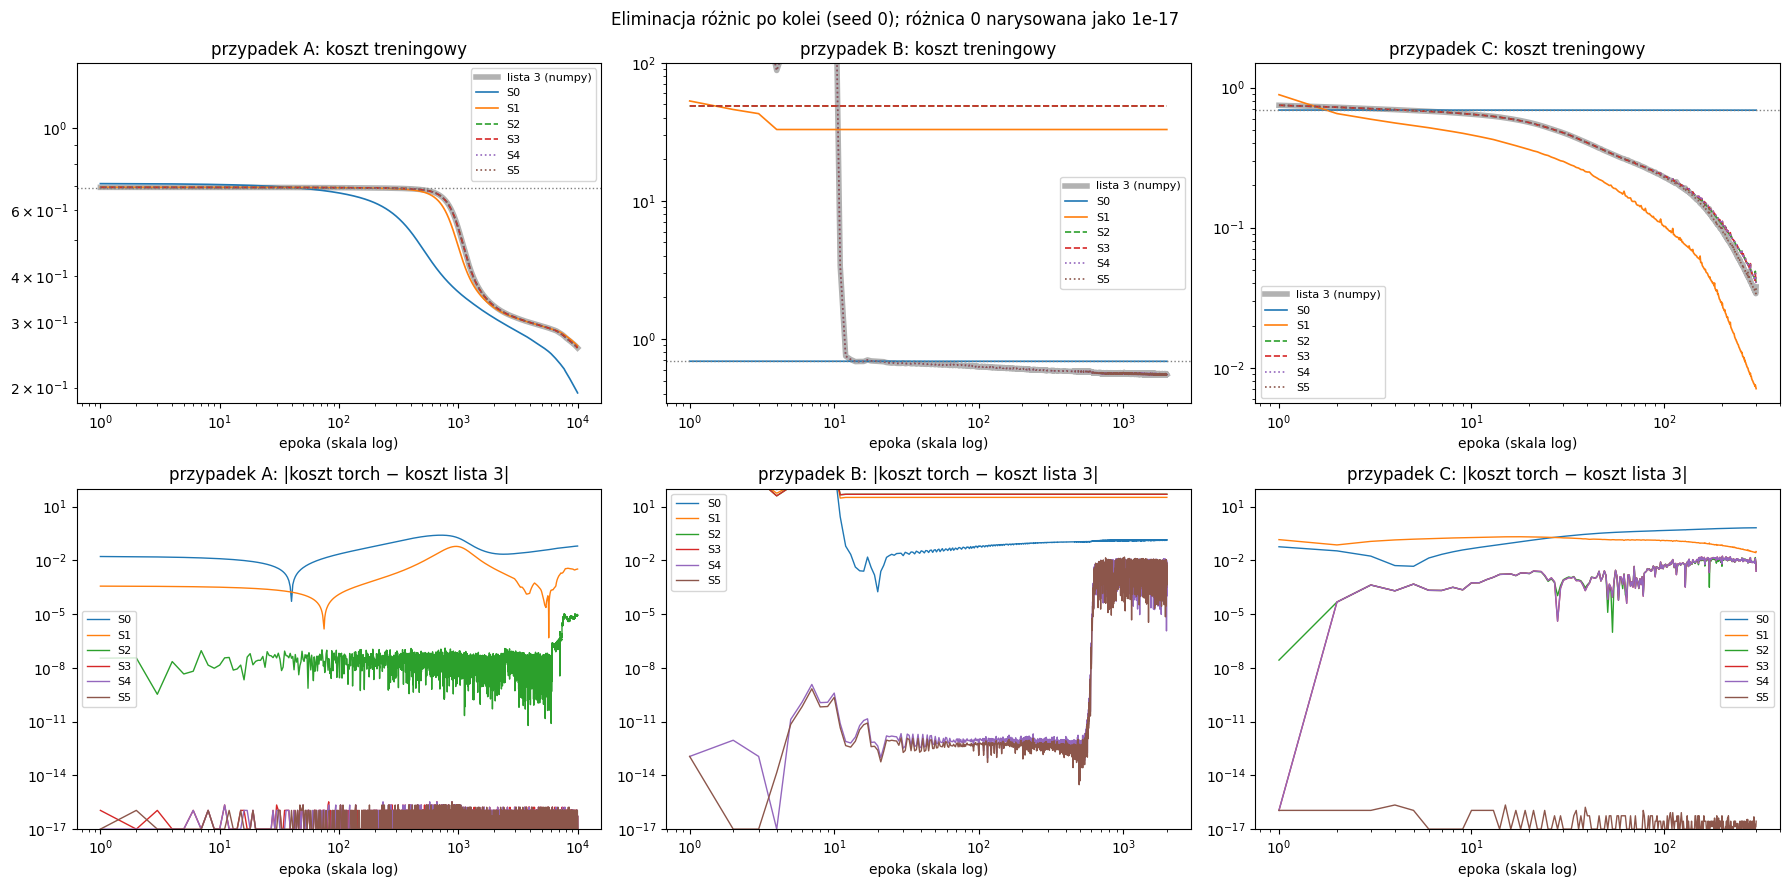

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for col, k in enumerate(CASES):
    ax = axes[0, col]
    ax.plot(np.arange(1, len(refs[k]["loss"]) + 1), refs[k]["loss"], color="k", lw=4, alpha=0.3, label="lista 3 (numpy)")
    for (name, _), ls in zip(cfgs, ["-", "-", "--", "--", ":", ":"]):
        ax.plot(np.arange(1, len(stage_runs[(k, name)]["loss"]) + 1), stage_runs[(k, name)]["loss"], ls=ls, lw=1.2, label=name.split(":")[0])
    ax.axhline(L_prior, color="gray", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(top=1e2 if k == "B" else 1.5)
    ax.set_title(f"przypadek {k}: koszt treningowy"); ax.set_xlabel("epoka (skala log)"); ax.legend(fontsize=8)
    ax = axes[1, col]
    for name, _ in cfgs:
        d = np.abs(stage_runs[(k, name)]["loss"] - refs[k]["loss"])
        ok = np.isfinite(d)
        ax.plot(np.arange(1, len(d) + 1)[ok], np.clip(d[ok], 1e-17, None), lw=1, label=name.split(":")[0])
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-17, 1e2)
    ax.set_title(f"przypadek {k}: |koszt torch − koszt lista 3|"); ax.set_xlabel("epoka (skala log)"); ax.legend(fontsize=8)
fig.suptitle("Eliminacja różnic po kolei (seed 0); różnica 0 narysowana jako 1e-17")
fig.tight_layout()
plt.show()

**Co dała każda poprawka:**

- **S0, sieć z tutorialu, zachowuje się inaczej niż lista 3.** Domyślna inicjalizacja `nn.Linear` to rozkład jednostajny ±1/√n_in
  (odchylenie ≈ 0.11 przy 28 wejściach), a nie N(0, 0.01):
  - **A:** wagi są ~10 razy większe niż w liście 3, więc plateau kończy się w epoce 262 zamiast 881, a F1 to 0.780 zamiast 0.828;
  - **C:** dla 5 warstw ReLU te wagi są ~2.5 razy za małe względem He, więc sieć **stoi na plateau** przez całe 300 epok (F1 = 0, w liście 3 0.730).
- **S1, ten sam rozkład wag:** zachowanie **podobne statystycznie** (A: to samo F1, plateau 775 zamiast 881), ale liczby są inne,
  bo torch i numpy losują z innych generatorów. W C koszt spada nawet szybciej niż w liście 3 (plateau 3 zamiast 16): przy innym losowaniu
  przebieg może wyglądać zupełnie inaczej.
- **S2, te same wagi (kopia z numpy):** krzywe kosztu pokrywają się na wykresie, ale tylko „na oko”. Kopia do float32 zaokrągla wagi do ~7 cyfr,
  więc różnica kosztu ~1e-8 rośnie w trakcie uczenia do 1e-5 (A, zielona linia).
- **S3, float64:** w A różnica spada do **~1e-16**, czyli do ostatniej cyfry liczby float64. Lepiej się nie da.
- **S4, `BCEWithLogitsLoss`:** w A i C bez znaczenia, w **B kluczowe**. Przy wagach z N(0, 1) logity mają setki, σ(z) to dokładnie 0 albo 1,
  a `Sigmoid` + `BCELoss` **zeruje gradient** (Δgrad = 1.0, czyli 100%; patrz poziom 1). Sieć w torchu się nie uczy (F1 0.065), w liście 3 tak (0.711).
  Po zmianie gradient zgadza się do 4e-16, F1 i koniec plateau są te same.
- **S5, ta sama kolejność paczek:** przy pełnym zbiorze (A, B) bez znaczenia. W C `shuffle=True` daje **inne paczki**, więc inną trajektorię
  uczenia (ΔW = 0.13, 3 pacjentów inaczej). Własny `Sampler` z permutacją numpy daje różnicę 2e-16 i identyczne predykcje.

**Przypadek B po wszystkich poprawkach** ma jeszcze różnicę kosztu 1.5e-2. Na dolnym wykresie różnica wynosi ~1e-12 aż do epoki ~600,
a potem nagle skacze. To nie jest kolejna różnica w implementacji, tylko niestabilne uczenie (sprawdzam to na poziomie 3 i w kontroli niżej).
Wynik końcowy jest ten sam: F1 0.711, 0 różnych predykcji.

## Poziom 3 – wagi krok po kroku

Po usunięciu różnic obie implementacje uczą się **obok siebie**: ta sama paczka, krok numpy, krok torcha i porównanie
wszystkich wag po **każdym** kroku. Sprawdzam, jak różnica rośnie w trakcie uczenia, dla float64 i float32,
na sześciu konfiguracjach z listy 3 (seed 0). Trzy ostatnie to przebiegi, które na poziomie 4 okażą się najmniej zgodne.

czas: 101 s


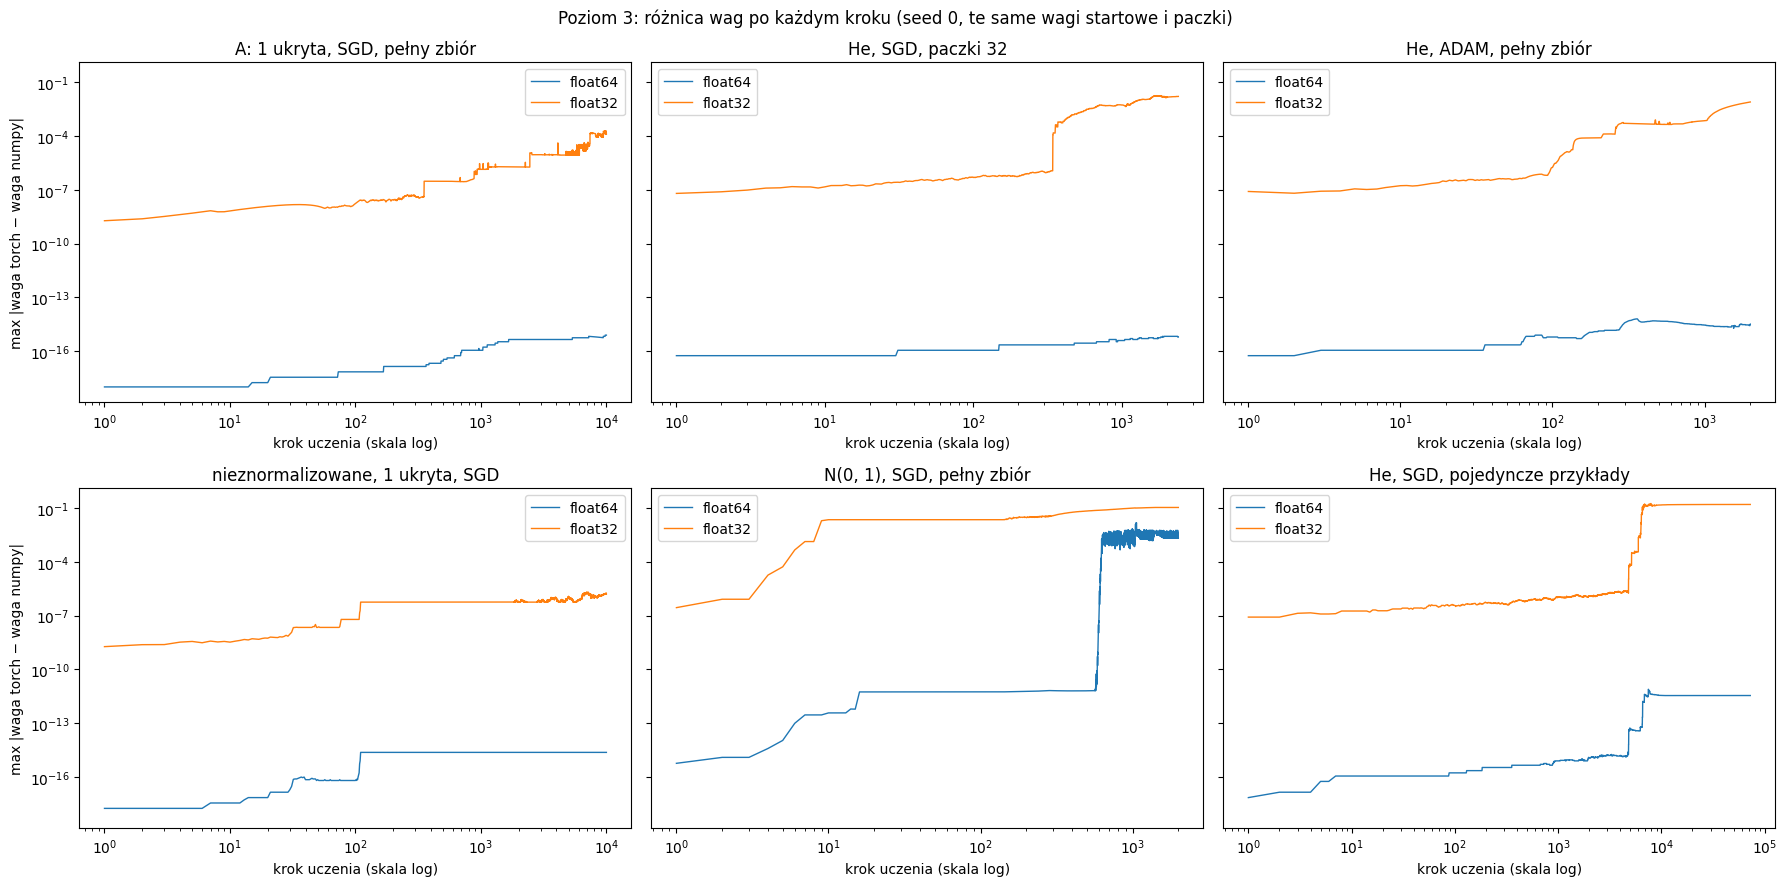

kroków po 1 kroku   po 100  po 1000 na końcu
konfiguracja                     precyzja                                              
A: 1 ukryta, SGD, pełny zbiór    float64    10000    2.7e-20  6.9e-18  1.1e-16  7.8e-16
                                 float32    10000    1.9e-09  1.7e-08  1.4e-06  1.3e-04
He, SGD, paczki 32               float64     2400    5.6e-17  1.1e-16  3.9e-16  6.1e-16
                                 float32     2400    6.3e-08  4.9e-07  5.5e-03  1.6e-02
He, ADAM, pełny zbiór            float64     2000    5.6e-17  6.1e-16  2.8e-15  3.2e-15
                                 float32     2000    8.1e-08  1.8e-06  7.2e-04  8.1e-03
nieznormalizowane, 1 ukryta, SGD float64    10000    1.7e-18  6.2e-17  2.3e-15  2.3e-15
                                 float32    10000    1.9e-09  6.1e-08  5.7e-07  1.6e-06
N(0, 1), SGD, pełny zbiór        float64     2000    5.7e-16  5.5e-12  4.6e-03  2.2e-03
                                 float32     2000    2.8e-07  2.3e-02  1.0e-01  1.1e-01
He, SGD, pojedyncze przykłady    float64    72600    6.9e-18  1.7e-16  7.8e-16  3.5e-12
                                 float32    72600    8.3e-08  3.7e-07  1.1e-06  1.6e-01

In [11]:
LOCK = {"A: 1 ukryta, SGD, pełny zbiór": dict(part=1, hidden=[n_features], raw=False, epochs=10000, bs=None, opt="SGD"),
        "He, SGD, paczki 32": dict(part=2, hidden=HIDDEN5, init="he", raw=False, epochs=300, bs=32, opt="SGD"),
        "He, ADAM, pełny zbiór": dict(part=2, hidden=HIDDEN5, init="he", raw=False, epochs=2000, bs=None, opt="ADAM"),
        "nieznormalizowane, 1 ukryta, SGD": dict(part=1, hidden=[n_features], raw=True, epochs=10000, bs=None, opt="SGD"),
        "N(0, 1), SGD, pełny zbiór": dict(part=2, hidden=HIDDEN5, init=1.0, raw=False, epochs=2000, bs=None, opt="SGD"),
        "He, SGD, pojedyncze przykłady": dict(part=2, hidden=HIDDEN5, init="he", raw=False, epochs=300, bs=1, opt="SGD")}


def lockstep(cfg, dtype, seed=0):
    torch.set_num_threads(1)
    nm = numpy_start(cfg, seed)
    tm = NeuralNetwork([n_features] + cfg["hidden"] + [1]).to(dtype)
    copy_weights(nm, tm)
    lf, loss_fn = lab3.SigmoidBCELoss(), nn.BCEWithLogitsLoss()
    opt_n = lab3_cz2.GD(0.01) if cfg["opt"] == "SGD" else lab3_cz2.Adam(0.001)
    opt_t = torch.optim.SGD(tm.parameters(), lr=0.01) if cfg["opt"] == "SGD" else torch.optim.Adam(tm.parameters(), lr=0.001)
    X = X_train_raw if cfg["raw"] else X_train
    Xt, yt = to_tensor(X, dtype), to_tensor(y_train, dtype).reshape(-1, 1)
    n = len(X)
    bs = n if cfg["bs"] is None else cfg["bs"]
    rng = np.random.default_rng(seed + 1000)
    diffs = []
    with np.errstate(all="ignore"):
        for epoch in range(cfg["epochs"]):
            order = rng.permutation(n) if bs < n else np.arange(n)
            for s in range(0, n, bs):
                b = order[s:s + bs]
                lf.forward(nm.forward(X[b]), y_train[b])
                nm.backward(lf.backward())
                opt_n.step(nm)
                loss_fn(tm(Xt[b]), yt[b]).backward()
                opt_t.step()
                opt_t.zero_grad()
                diffs.append(weights_diff(tm, nm))
    return np.array(diffs)


t0 = time.time()
lock_jobs = [(name, dt) for name in LOCK for dt in [torch.float64, torch.float32]]
lock_out = dict(zip(lock_jobs, Parallel(n_jobs=N_JOBS)(delayed(lockstep)(LOCK[n], d) for n, d in lock_jobs)))
print(f"czas: {time.time() - t0:.0f} s")

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
for ax, name in zip(axes.ravel(), LOCK):
    for dt in [torch.float64, torch.float32]:
        d = lock_out[(name, dt)]
        ok = np.isfinite(d)
        ax.plot(np.arange(1, len(d) + 1)[ok], np.clip(d[ok], 1e-18, None), lw=1, label=str(dt).replace("torch.", ""))
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(name); ax.set_xlabel("krok uczenia (skala log)"); ax.legend()
for ax in axes[:, 0]:
    ax.set_ylabel("max |waga torch − waga numpy|")
fig.suptitle("Poziom 3: różnica wag po każdym kroku (seed 0, te same wagi startowe i paczki)")
fig.tight_layout()
plt.show()

def at(d, k):
    return d[min(k, len(d)) - 1]
pd.DataFrame([{"konfiguracja": n, "precyzja": str(dt).replace("torch.", ""), "kroków": len(d),
               "po 1 kroku": f"{at(d, 1):.1e}", "po 100": f"{at(d, 100):.1e}", "po 1000": f"{at(d, 1000):.1e}",
               "na końcu": f"{d[-1]:.1e}"} for (n, dt), d in lock_out.items()]).set_index(["konfiguracja", "precyzja"])

- **float64, przebiegi stabilne** (A, He z paczkami, He z ADAM, dane nieznormalizowane w seedzie 0): różnica wag zostaje na poziomie
  **1e-16 – 3e-15** przez tysiące kroków (A: 10 000 kroków, na końcu 7.8e-16). Obie implementacje liczą to samo, a różnią się tylko ostatnie bity zaokrągleń.
- **float32:** różnica jest już przed pierwszym krokiem (1e-9 – 1e-7, zaokrąglenie przy kopiowaniu wag) i **rośnie we wszystkich konfiguracjach**,
  do 1e-4 – 1e-1 na końcu. Żeby mieć „te same wagi”, float64 jest konieczny.
- **float64, przebiegi niestabilne:**
  - N(0, 1): różnica rośnie z ~1e-11 do ~1e-3 w okolicy kroku 600;
  - pojedyncze przykłady: z ~1e-14 do 1e-12 w okolicy kroku 5000.

  W tych momentach koszt gwałtownie się zmienia, a malutka różnica się wzmacnia. Ten sam skok jest widoczny w float32.

## Poziom 4 – wszystkie eksperymenty z listy 3

Każdy przebieg z listy 3 (wszystkie 20 różnych konfiguracji, seedy 0, 1, 2) liczę dwa razy:
- oryginalnym kodem listy 3 (`lab3.train`, `lab3_cz2.train`);
- wersją w PyTorchu ze wszystkimi poprawkami S1–S5: float64, te same wagi, `BCEWithLogitsLoss`, `torch.optim`,
  `DataLoader` z tą samą kolejnością paczek.

Wersja PyTorch zwraca historię w tym samym formacie co lista 3 (koszt train i test, F1 w każdej epoce, w części 2
także normy gradientu każdej warstwy), więc porównuję wszystko epoka po epoce.

In [12]:
def train_torch_cz1(hidden, X_tr, X_te, seed, epochs=lab3.EPOCHS, lr=lab3.LR):
    # odpowiednik lab3.train: pełny zbiór, SGD, N(0, 0.01)
    nm = lab3.MLP([n_features] + hidden + [1], seed=seed)
    tm = NeuralNetwork([n_features] + hidden + [1]).double()
    copy_weights(nm, tm)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(tm.parameters(), lr=lr)
    X, Xte = to_tensor(X_tr), to_tensor(X_te)
    y, yte = to_tensor(y_train).reshape(-1, 1), to_tensor(y_test).reshape(-1, 1)
    h = {"train_loss": [], "test_loss": [], "f1": []}
    for epoch in range(epochs):
        tm.train()
        loss = loss_fn(tm(X), y)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        h["train_loss"].append(loss.item())
        tm.eval()
        with torch.no_grad():
            z = tm(Xte)
            h["test_loss"].append(loss_fn(z, yte).item())
            h["f1"].append(f1_score(y_test, (z.numpy().ravel() >= 0).astype(int), zero_division=0))
    return tm, {k: np.array(v) for k, v in h.items()}


def train_torch_cz2(hidden, init, opt, batch_size=None, epochs=1000, seed=0):
    # odpowiednik lab3_cz2.train: inicjalizacja, SGD / ADAM, tryby uczenia, statystyki warstw
    tm = NeuralNetwork([n_features] + hidden + [1]).double()
    copy_weights(lab3_cz2.build_model(hidden, init, seed), tm)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(tm.parameters(), lr=lab3_cz2.LR_GD) if opt == "SGD" else torch.optim.Adam(tm.parameters(), lr=lab3_cz2.LR_ADAM)
    X, Xte = to_tensor(X_train), to_tensor(X_test)
    y, yte = to_tensor(y_train).reshape(-1, 1), to_tensor(y_test).reshape(-1, 1)
    n = len(X)
    bs = n if batch_size is None else batch_size
    loader = DataLoader(TensorDataset(X, y), batch_size=None, sampler=SameOrderBatches(n, bs, seed))
    h = {"train_loss": [], "test_loss": [], "f1": [], "grad_norms": [], "diverged_at": None}

    def evaluate():
        tm.zero_grad()
        loss = loss_fn(tm(X), y)
        loss.backward()                                   # pełny gradient tylko do statystyk (bez kroku)
        h["grad_norms"].append([l.weight.grad.norm().item() for l in tm.linear_layers()])
        tm.zero_grad()
        with torch.no_grad():
            z = tm(Xte)
            h["test_loss"].append(loss_fn(z, yte).item())
            h["f1"].append(f1_score(y_test, (z.numpy().ravel() >= 0).astype(int), zero_division=0))
        h["train_loss"].append(loss.item())

    evaluate()
    for epoch in range(1, epochs + 1):
        for xb, yb in loader:
            loss = loss_fn(tm(xb), yb)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        evaluate()
        L = h["train_loss"][-1]
        if not np.isfinite(L) or L > lab3_cz2.DIVERGE_FACTOR * max(h["train_loss"][0], 1.0):
            h["diverged_at"] = epoch
            break
    pad = epochs + 1 - len(h["train_loss"])
    for k in ["train_loss", "test_loss", "f1"]:
        h[k] = np.array(h[k] + [np.nan] * pad)
    h["grad_norms"] = np.vstack([np.array(h["grad_norms"]), np.full((pad, len(tm.linear_layers())), np.nan)])
    return tm, h


EXP = []   # (grupa, nazwa, część, parametry)
for hh in [2, 4, n_features, 128, 512]:
    EXP.append(("1: rozmiar warstwy ukrytej", f"h = {hh}", 1, dict(hidden=[hh], raw=False)))
EXP.append(("2: normalizacja", "znormalizowane (h = 28)", 1, dict(hidden=[n_features], raw=False)))
EXP.append(("2: normalizacja", "nieznormalizowane (h = 28)", 1, dict(hidden=[n_features], raw=True)))
for d in [0, 1, 2, 3]:
    EXP.append(("3: liczba warstw", lab3.layers_label(d), 1, dict(hidden=[n_features] * d, raw=False)))
for init, lab in [(0.01, "N(0, 0.01)"), ("he", "He"), (1.0, "N(0, 1)"), (10.0, "N(0, 10)")]:
    EXP.append(("4: inicjalizacja (GD)", lab, 2, dict(init=init, opt="SGD", bs=None, epochs=2000)))
for init, lab in [(0.01, "N(0, 0.01)"), ("he", "He"), (1.0, "N(0, 1)")]:
    EXP.append(("5: ADAM", lab, 2, dict(init=init, opt="ADAM", bs=None, epochs=2000)))
for init, lab in [("he", "He"), (0.01, "N(0, 0.01)")]:
    for bs, mode in [(None, "pełny zbiór"), (32, "paczki 32"), (1, "pojedyncze")]:
        EXP.append(("6: tryby uczenia (GD)", f"{lab}, {mode}", 2, dict(init=init, opt="SGD", bs=bs, epochs=300)))


def compare_run(group, name, part, p, seed):
    torch.set_num_threads(1)
    t0 = time.perf_counter()
    with np.errstate(all="ignore"):
        if part == 1:
            Xtr, Xte = (X_train_raw, X_test_raw) if p["raw"] else (X_train, X_test)
            nm, hn = lab3.train(p["hidden"], Xtr, Xte, seed)
            t1 = time.perf_counter()
            tm, ht = train_torch_cz1(p["hidden"], Xtr, Xte, seed)
            gn = np.nan
        else:
            Xte = X_test
            np_opt = lab3_cz2.GD() if p["opt"] == "SGD" else lab3_cz2.Adam()
            nm, hn = lab3_cz2.train(HIDDEN5, p["init"], np_opt, p["bs"], p["epochs"], seed)
            t1 = time.perf_counter()
            tm, ht = train_torch_cz2(HIDDEN5, p["init"], p["opt"], p["bs"], p["epochs"], seed)
            gn = rel_diff(ht["grad_norms"], hn["grad_norms"])
        t2 = time.perf_counter()
        pn, pt = (nm.predict_proba(Xte) >= 0.5).astype(int), (tm.predict_proba(Xte) >= 0.5).astype(int)
        div = (hn.get("diverged_at"), ht.get("diverged_at"))
    return {"grupa": group, "konfiguracja": name, "seed": seed,
            "koszt numpy": hn["train_loss"][-1],
            "koszt torch": ht["train_loss"][-1],
            "F1 numpy": f1_score(y_test, pn, zero_division=0), "F1 torch": f1_score(y_test, pt, zero_division=0),
            "plateau numpy": plateau(hn["train_loss"]), "plateau torch": plateau(ht["train_loss"]),
            "Δkoszt": max(rel_diff(ht["train_loss"], hn["train_loss"]), rel_diff(ht["test_loss"], hn["test_loss"])),
            "ΔF1 (krzywa)": rel_diff(ht["f1"], hn["f1"]), "Δ|dW|": gn, "ΔW": weights_diff(tm, nm),
            "różne pred.": int(np.sum(pn != pt)), "rozbieżność numpy/torch": div,
            "czas numpy": t1 - t0, "czas torch": t2 - t1, "hn": hn["train_loss"], "ht": ht["train_loss"]}


t0 = time.time()
res4 = Parallel(n_jobs=N_JOBS)(delayed(compare_run)(g, n, part, p, s) for g, n, part, p in EXP for s in lab3.SEEDS)
df4 = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hn", "ht")} for r in res4])
print(f"przebiegów: {len(df4)} (x2 implementacje), czas: {time.time() - t0:.0f} s")


def side_by_side(df):
    g = df.groupby(["grupa", "konfiguracja"], sort=False)
    f3 = lambda c: g[c].mean().map(lambda v: "—" if np.isnan(v) else f"{v:.3f}")
    fp = lambda c: g[c].mean().map(lambda v: "brak" if np.isnan(v) else f"{v:.0f}")
    fe = lambda c: g[c].max().map(lambda v: "—" if np.isnan(v) else f"{v:.1e}")
    return pd.DataFrame({"koszt numpy": f3("koszt numpy"), "koszt torch": f3("koszt torch"),
                         "F1 numpy": f3("F1 numpy"), "F1 torch": f3("F1 torch"),
                         "plateau numpy": fp("plateau numpy"), "plateau torch": fp("plateau torch"),
                         "max Δkoszt": fe("Δkoszt"), "max ΔF1 (krzywa)": fe("ΔF1 (krzywa)"),
                         "max Δ|dW|": fe("Δ|dW|"), "max ΔW": fe("ΔW"),
                         "różne pred. (z 183)": g["różne pred."].sum()})

side_by_side(df4)

przebiegów: 72 (x2 implementacje), czas: 214 s


koszt numpy koszt torch F1 numpy F1 torch plateau numpy plateau torch max Δkoszt max ΔF1 (krzywa) max Δ|dW|   max ΔW  różne pred. (z 183)
grupa                      konfiguracja                                                                                                                                                        
1: rozmiar warstwy ukrytej h = 2                            0.296       0.296    0.816    0.816          1882          1882    5.6e-16          0.0e+00         —  8.0e-16                    0
                           h = 4                            0.276       0.276    0.821    0.821          1360          1360    4.4e-16          0.0e+00         —  5.6e-16                    0
                           h = 28                           0.261       0.261    0.832    0.832           907           907    4.4e-16          0.0e+00         —  7.8e-16                    0
                           h = 128                          0.239       0.239    0.823    0.823           609           609    3.3e-16          0.0e+00         —  4.4e-16                    0
                           h = 512                          0.218       0.218    0.800    0.800           402           402    3.3e-16          0.0e+00         —  4.4e-16                    0
2: normalizacja            znormalizowane (h = 28)          0.261       0.261    0.832    0.832           907           907    4.4e-16          0.0e+00         —  7.8e-16                    0
                           nieznormalizowane (h = 28)       0.529       0.526    0.658    0.658           326           326    8.1e-02          2.2e-01         —  1.0e-02                    0
3: liczba warstw           0 warstw ukrytych                0.308       0.308    0.836    0.836            48            48    3.3e-16          0.0e+00         —  2.6e-16                    0
                           1 warstwa ukryta                 0.261       0.261    0.832    0.832           907           907    4.4e-16          0.0e+00         —  7.8e-16                    0
                           2 warstwy ukryte                 0.386       0.386    0.838    0.838          9031          9031    7.8e-16          0.0e+00         —  5.6e-16                    0
                           3 warstwy ukryte                 0.690       0.690    0.000    0.000          brak          brak    5.6e-16          0.0e+00         —  1.0e-17                    0
4: inicjalizacja (GD)      N(0, 0.01)                       0.690       0.690    0.000    0.000          brak          brak    4.4e-16          0.0e+00   1.7e-19  5.6e-17                    0
                           He                               0.044       0.044    0.784    0.784           108           108    7.8e-16          0.0e+00   2.4e-16  4.4e-16                    0
                           N(0, 1)                          0.284       0.284    0.444    0.444           128           128    2.7e-02          0.0e+00   1.2e+00  2.2e-03                    0
                           N(0, 10)                             —           —    0.419    0.419          brak          brak    2.3e-16          0.0e+00   5.1e-16  1.7e-13                    0
5: ADAM                    N(0, 0.01)                       0.040       0.040    0.764    0.764            68            68    2.3e-09          0.0e+00   3.1e-08  7.2e-09                    0
                           He                               0.000       0.000    0.756    0.756            16            16    1.4e-15          0.0e+00   4.9e-16  3.2e-15                    0
                           N(0, 1)                          0.000       0.000    0.659    0.659           325           325    3.4e-14          0.0e+00   6.6e-12  6.6e-14                    0
6: tryby uczenia (GD)      He, pełny zbiór                  0.393       0.393    0.779    0.779           108           108    3.3e-16          0.0e+00   1.7e-16  2.2e-16                    0
                      

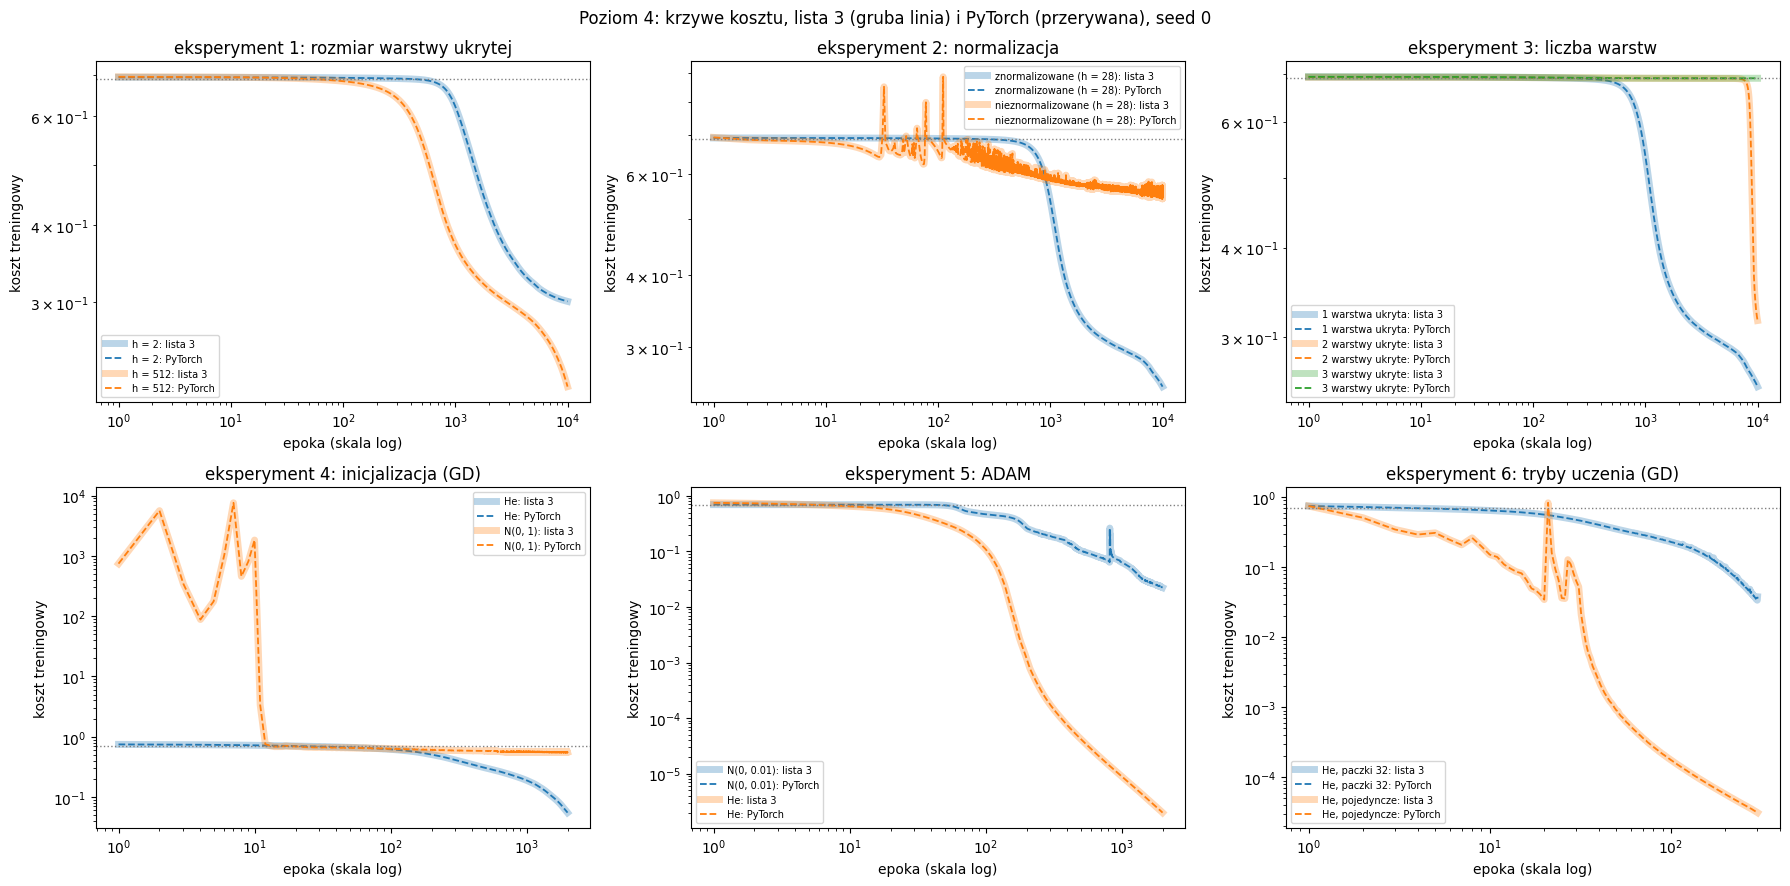

,zgodność
przebiegów,72
identyczne predykcje,72
identyczne F1,72
ten sam koniec plateau,72
rozbieżność w tej samej epoce,72
ΔW < 1e-12,64


In [13]:
picks = [("1: rozmiar warstwy ukrytej", ["h = 2", "h = 512"]), ("2: normalizacja", ["znormalizowane (h = 28)", "nieznormalizowane (h = 28)"]),
         ("3: liczba warstw", ["1 warstwa ukryta", "2 warstwy ukryte", "3 warstwy ukryte"]),
         ("4: inicjalizacja (GD)", ["He", "N(0, 1)"]), ("5: ADAM", ["N(0, 0.01)", "He"]), ("6: tryby uczenia (GD)", ["He, paczki 32", "He, pojedyncze"])]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (grp, names) in zip(axes.ravel(), picks):
    for name in names:
        r = next(r for r in res4 if r["grupa"] == grp and r["konfiguracja"] == name and r["seed"] == 0)
        x = np.arange(1, len(r["hn"]) + 1)
        line, = ax.plot(x, r["hn"], lw=5, alpha=0.3, label=f"{name}: lista 3")
        ax.plot(x, r["ht"], ls="--", lw=1.3, color=line.get_color(), label=f"{name}: PyTorch")
    ax.axhline(L_prior, color="gray", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"eksperyment {grp}"); ax.set_xlabel("epoka (skala log)")
    ax.set_ylabel("koszt treningowy"); ax.legend(fontsize=7)
fig.suptitle("Poziom 4: krzywe kosztu, lista 3 (gruba linia) i PyTorch (przerywana), seed 0")
fig.tight_layout()
plt.show()

summary = {"przebiegów": len(df4),
           "identyczne predykcje": int((df4["różne pred."] == 0).sum()),
           "identyczne F1": int((np.abs(df4["F1 numpy"] - df4["F1 torch"]) < 1e-12).sum()),
           "ten sam koniec plateau": int(((df4["plateau numpy"] == df4["plateau torch"]) | (df4["plateau numpy"].isna() & df4["plateau torch"].isna())).sum()),
           "rozbieżność w tej samej epoce": f"{int((df4['rozbieżność numpy/torch'].map(lambda d: d[0] == d[1])).sum())}",
           "ΔW < 1e-12": int((df4["ΔW"] < 1e-12).sum())}
pd.Series(summary, name="zgodność").to_frame()

- **We wszystkich 72 przebiegach** (24 konfiguracje × 3 seedy) PyTorch i lista 3 dają **identyczne predykcje testowe, identyczne F1,
  ten sam koniec plateau i rozbieżność w tej samej epoce**. W tabeli kolumny numpy i torch są takie same co do cyfry, poza jednym miejscem:
  koszt dla danych nieznormalizowanych (0.529 vs 0.526).
- **64 z 72 przebiegów** mają wagi końcowe zgodne do < 1e-12 (zwykle ~1e-16). Gradient przed uczeniem jest zawsze zgodny
  (to samo pokazał poziom 2), a w tych przebiegach także normy gradientu każdej warstwy (Δ|dW|) w każdej epoce zgadzają się do ~1e-16.
- **Pozostałe 8 przebiegów** to konfiguracje niestabilne. W nich różnica wag dochodzi do 1e-2 (dane nieznormalizowane, seed 2),
  2e-3 (N(0, 1), seed 0) i 2e-4 (pojedyncze przykłady, seed 2):
  - dane nieznormalizowane: koszt skacze przez całe uczenie;
  - SGD z N(0, 1): ogromne logity na starcie;
  - ADAM z N(0, 0.01): wyjście z plateau przy gradientach ~1e-8;
  - pojedyncze przykłady: 72 600 kroków.
- Przy N(0, 10) numpy dostaje `nan` w ReLU (`inf · 0`, poziom 1), a torch 0. Mimo to oba przebiegi rozbiegają się w 1. epoce,
  więc ta różnica **nie zmieniła żadnego wyniku**.

### Kontrola przebiegów, które się rozjechały

Czy rozjazd w kilku konfiguracjach to błąd w implementacji, czy cecha samego uczenia? Test: uczę **numpy przeciwko numpy**,
gdzie w drugiej kopii każdą wagę początkową mnożę przez (1 + 1e-15), czyli zmieniam ją na ostatniej cyfrze.
To mniej więcej tyle, ile różnią się zaokrąglenia numpy i PyTorcha. Jeśli numpy sam ze sobą rozjeżdża się tak samo
jak z PyTorchem, przyczyną jest czułość uczenia na zaokrąglenia, a nie różnica implementacji.

In [14]:
def numpy_run(cfg, seed, eps):
    # pętla jak w lab3.train / lab3_cz2.train, z opcjonalnym zaburzeniem wag startowych
    nm = numpy_start(cfg, seed)
    for l in np_linear(nm):
        l.W *= 1 + eps
    lf = lab3.SigmoidBCELoss()
    opt = lab3_cz2.GD(0.01) if cfg["opt"] == "SGD" else lab3_cz2.Adam(0.001)
    X = X_train_raw if cfg["raw"] else X_train
    n = len(X)
    bs = n if cfg["bs"] is None else cfg["bs"]
    rng = np.random.default_rng(seed + 1000)
    losses = []
    with np.errstate(all="ignore"):
        for epoch in range(cfg["epochs"]):
            order = rng.permutation(n) if bs < n else np.arange(n)
            for s in range(0, n, bs):
                b = order[s:s + bs]
                losses.append(lf.forward(nm.forward(X[b]), y_train[b]))
                nm.backward(lf.backward())
                opt.step(nm)
        Xte = X_test_raw if cfg["raw"] else X_test
        pred = (nm.predict_proba(Xte) >= 0.5).astype(int)
    return [l.W.copy() for l in np_linear(nm)], np.array(losses), pred


def control(name, cfg, seed):
    Wa, La, pa = numpy_run(cfg, seed, 0.0)
    Wb, Lb, pb = numpy_run(cfg, seed, 1e-15)
    return {"konfiguracja": name, "seed": seed, "ΔW numpy vs numpy(1+1e-15)": max(rel_diff(a, b) for a, b in zip(Wa, Wb)),
            "Δkoszt": rel_diff(La, Lb), "różne pred.": int(np.sum(pa != pb))}

CTRL = {"nieznormalizowane (h = 28)": ("2: normalizacja", LOCK["nieznormalizowane, 1 ukryta, SGD"]),
        "N(0, 1)": ("4: inicjalizacja (GD)", LOCK["N(0, 1), SGD, pełny zbiór"]),
        "N(0, 0.01)": ("5: ADAM", dict(part=2, hidden=HIDDEN5, init=0.01, raw=False, epochs=2000, bs=None, opt="ADAM")),
        "He, pojedyncze": ("6: tryby uczenia (GD)", LOCK["He, SGD, pojedyncze przykłady"]),
        "He, paczki 32": ("6: tryby uczenia (GD)", LOCK["He, SGD, paczki 32"])}
t0 = time.time()
ctrl = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(control)(n, c, s) for n, (_, c) in CTRL.items() for s in lab3.SEEDS))
print(f"czas: {time.time() - t0:.0f} s")
torch_vs_np = {n: df4[(df4.grupa == g) & (df4.konfiguracja == n)].set_index("seed")["ΔW"] for n, (g, _) in CTRL.items()}
ctrl["ΔW torch vs numpy (poziom 4)"] = [torch_vs_np[r.konfiguracja][r.seed] for r in ctrl.itertuples()]
ctrl.set_index(["konfiguracja", "seed"])[["ΔW torch vs numpy (poziom 4)", "ΔW numpy vs numpy(1+1e-15)", "różne pred."]].map(
    lambda v: f"{v:.1e}" if isinstance(v, float) else v)

czas: 21 s


ΔW torch vs numpy (poziom 4) ΔW numpy vs numpy(1+1e-15)  różne pred.
konfiguracja               seed                                                                     
nieznormalizowane (h = 28) 0                         2.3e-15                    2.4e-15            0
                           1                         2.8e-11                    8.4e-11            0
                           2                         1.0e-02                    1.7e-02            1
N(0, 1)                    0                         2.2e-03                    1.8e-03            0
                           1                         5.2e-14                    0.0e+00            0
                           2                         1.8e-12                    2.4e-11            0
N(0, 0.01)                 0                         7.2e-09                    1.2e-07            0
                           1                         3.7e-11                    1.2e-11            0
                           2                         2.8e-14                    8.4e-13            0
He, pojedyncze             0                         3.5e-12                    6.7e-12            0
                           1                         2.7e-14                    2.1e-14            0
                           2                         1.8e-04                    1.1e-04            0
He, paczki 32              0                         6.1e-16                    1.6e-15            0
                           1                         6.7e-16                    2.1e-15            0
                           2                         6.7e-16                    1.9e-15            0

- W każdej rozjeżdżającej się konfiguracji **numpy sam ze sobą** (wagi zmienione o 1e-15) rozjeżdża się **tak samo jak z PyTorchem**,
  w tym samym rzędzie wielkości i w tych samych seedach:

  | konfiguracja, seed | torch vs numpy | numpy vs numpy (1 + 1e-15) |
  |---|---|---|
  | nieznormalizowane, seed 2 | 1.0e-2 | 1.7e-2 |
  | SGD N(0, 1), seed 0 | 2.2e-3 | 1.8e-3 |
  | pojedyncze przykłady, seed 2 | 1.8e-4 | 1.1e-4 |

  W konfiguracji stabilnej (He, paczki 32) oba porównania dają ~1e-15.
- Zaburzenie wag numpy o 1e-15 zmieniło nawet jedną predykcję (dane nieznormalizowane, seed 2), a PyTorch żadnej.
- Wniosek: pozostałe różnice **nie wynikają z różnicy w implementacji**, tylko z tego, że te przebiegi są wrażliwe na najmniejsze
  zaokrąglenia (inna kolejność sumowania w bibliotekach numpy i torcha). Takiej różnicy nie da się usunąć, bo zmiana ostatniego bitu
  w samym numpy daje ten sam efekt.

### Czas obliczeń: numpy vs PyTorch

In [15]:
t = df4.groupby("grupa", sort=False)[["czas numpy", "czas torch"]].mean()
t["torch / numpy"] = t["czas torch"] / t["czas numpy"]
display(t.round(2))
print(f"średnio na przebieg: numpy {df4['czas numpy'].mean():.1f} s, torch {df4['czas torch'].mean():.1f} s")

,czas numpy,czas torch,torch / numpy
grupa,,,
1: rozmiar warstwy ukrytej,6.37,24.94,3.91
2: normalizacja,2.42,23.15,9.58
3: liczba warstw,3.07,22.22,7.25
4: inicjalizacja (GD),1.96,5.74,2.93
5: ADAM,3.74,10.59,2.83
6: tryby uczenia (GD),3.92,19.41,4.96


średnio na przebieg: numpy 3.8 s, torch 18.0 s


- **PyTorch jest tu 3–10 razy wolniejszy niż numpy** (średnio 18 s zamiast 3.8 s na przebieg). Macierze są malutkie (242 × 28), więc samo liczenie
  trwa mikrosekundy, a czas zjada obsługa każdej operacji: budowa grafu, autograd, `DataLoader`, optymalizator. Najgorzej wypada część 1
  (10 000 epok z ewaluacją w każdej) i pojedyncze przykłady (72 600 kroków).
- Czasy w tabeli są mierzone przy 8 przebiegach liczonych jednocześnie, więc są większe niż przy liczeniu po kolei. Osobny pomiar po kolei
  na tym samym komputerze (i7-10700KF): lista 3 część 1 + 2 to 137 + 129 s, ta sama replikacja w PyTorchu 220 + 483 s.
- Przy CIFAR10 (część 2) ten narzut przestaje mieć znaczenie: paczka to mnożenie macierzy 128 × 3072 × 512, a epoka trwa ~2–3 s.

## Wnioski – część 1

- **Sieć z listy 3 da się odtworzyć w PyTorchu dokładnie**, do ostatniej cyfry float64. Trzeba jednak usunąć 4 różnice względem kodu z tutorialu:
  1. **wagi początkowe**: ten sam rozkład nie wystarcza (inne generatory), wagi trzeba skopiować z numpy;
  2. **float64** zamiast float32: w float32 wagi różnią się już po kopiowaniu, a różnica rośnie do 1e-4 – 1e-1;
  3. **`BCEWithLogitsLoss`** zamiast `Sigmoid` + `BCELoss`: przy dużych logitach osobny sigmoid zeruje gradient;
  4. **ta sama kolejność paczek**: `DataLoader(shuffle=True)` daje inną trajektorię uczenia.
- **Najbardziej wynik zmieniają funkcja kosztu i inicjalizacja.** Zmieniają zachowanie jakościowo: sieć się uczy albo nie, zostaje na plateau
  albo z niego wychodzi. float32 i kolejność paczek zmieniają szczegóły.
- **Sama ta sama architektura i ten sam rozkład wag** dają podobieństwo tylko **statystyczne**: podobne F1 i podobny koniec plateau. Identyczny przebieg
  wymaga identycznych liczb.
- **Sprawdzenie na 4 poziomach** (wersja końcowa, float64):

  | poziom | wynik |
  |---|---|
  | pojedyncze operacje | koszt i dL/dz: różnica ~1e-19, Linear (wyjście, dW, db, dx) ≤ 9e-16, ReLU w zerze ta sama |
  | jeden krok | logity, koszt, gradienty i wagi po kroku SGD / ADAM: ≤ 6e-15 |
  | wagi krok po kroku | przebiegi stabilne: ≤ 3e-15 po tysiącach kroków |
  | eksperymenty z listy 3 | 72 / 72 przebiegów: te same predykcje, F1, koniec plateau, rozbieżność |

- **Czego nie udało się usunąć:** różnic zaokrągleń (~1e-16), które w kilku niestabilnych przebiegach rosną do 1e-4 – 1e-2.
  Kontrola numpy kontra numpy pokazała, że to cecha tych przebiegów, a nie implementacji. Na tym zbiorze nie zmieniło to żadnej predykcji.

---
# CZĘŚĆ 2 – klasyfikacja CIFAR10 (baseline)

Z listy 3 wiem, że dla sieci z ReLU działają: dane znormalizowane, inicjalizacja dopasowana do ReLU (He)
i ADAM zamiast zwykłego gradientu. Sprawdzam, czy te wnioski przenoszą się na dużo większy problem.
Architekturę biorę z tutorialu (2 warstwy ukryte po 512), z wejściem 3 · 32 · 32 = 3072 zamiast 28 · 28.

- 5000 obrazków ze zbioru treningowego (po 500 z każdej klasy) odkładam na **walidację**: na niej wybieram wariant uczenia i epokę;
- **zbiór testowy** jest użyty tylko raz, na końcu.

trening 45000, walidacja 5000, test 10000, obrazek (3, 32, 32)
średnie kanałów RGB: [0.4913 0.4822 0.4465]  odchylenia: [0.247  0.2433 0.2616]
obrazków na klasę (trening): [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]


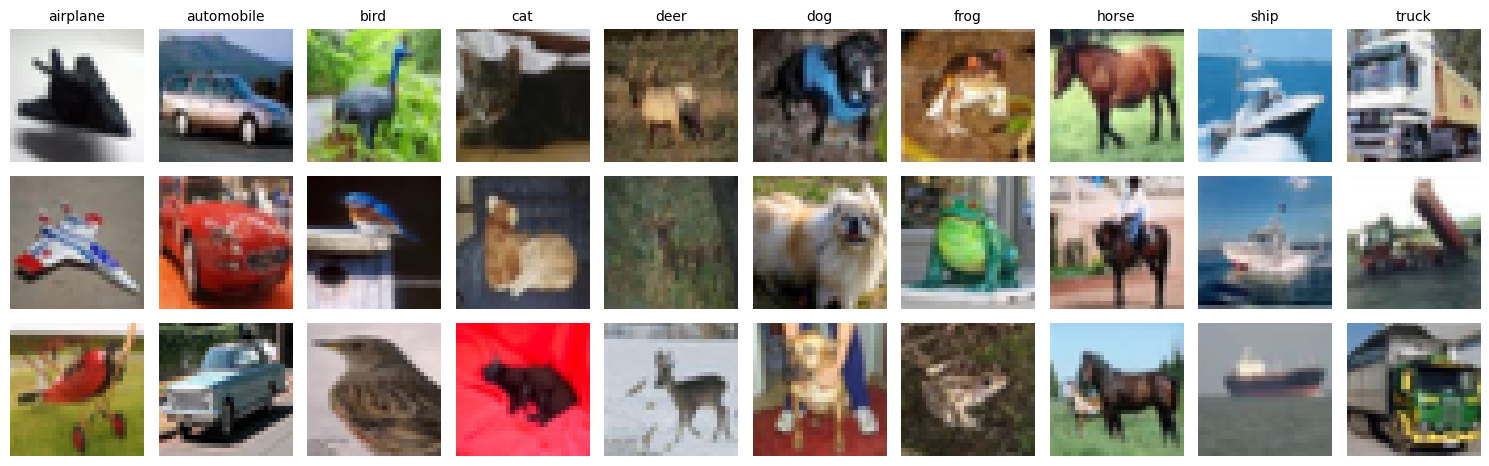

In [16]:
from torchvision import datasets
from sklearn.model_selection import train_test_split

torch.set_num_threads(os.cpu_count() // 2)
cifar_train = datasets.CIFAR10(root="data", train=True, download=True)
cifar_test = datasets.CIFAR10(root="data", train=False, download=True)
classes = cifar_train.classes

Xc = torch.tensor(cifar_train.data, dtype=torch.float32) / 255          # (50000, 32, 32, 3)
yc = torch.tensor(cifar_train.targets)
Xc_test = torch.tensor(cifar_test.data, dtype=torch.float32) / 255
yc_test = torch.tensor(cifar_test.targets)

idx_tr, idx_val = train_test_split(np.arange(len(yc)), test_size=5000, stratify=yc.numpy(), random_state=67)
mean, std = Xc[idx_tr].mean(dim=(0, 1, 2)), Xc[idx_tr].std(dim=(0, 1, 2))   # normalizacja kanałów RGB tylko z treningu
prep = lambda x: ((x - mean) / std).permute(0, 3, 1, 2)                       # -> (N, 3, 32, 32)
train_ds = TensorDataset(prep(Xc[idx_tr]), yc[idx_tr])
val_ds = TensorDataset(prep(Xc[idx_val]), yc[idx_val])
test_ds = TensorDataset(prep(Xc_test), yc_test)
print(f"trening {len(train_ds)}, walidacja {len(val_ds)}, test {len(test_ds)}, obrazek {tuple(train_ds[0][0].shape)}")
print("średnie kanałów RGB:", mean.numpy().round(4), " odchylenia:", std.numpy().round(4))
print("obrazków na klasę (trening):", np.bincount(yc[idx_tr].numpy()))

fig, axes = plt.subplots(3, 10, figsize=(15, 4.8))
for c in range(10):
    for r, i in enumerate(np.where(np.array(cifar_train.targets) == c)[0][:3]):
        axes[r, c].imshow(cifar_train.data[i]); axes[r, c].axis("off")
    axes[0, c].set_title(classes[c], fontsize=10)
fig.tight_layout()
plt.show()

In [17]:
class CifarNet(nn.Module):
    def __init__(self, init="default"):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
            nn.Linear(512, 512), nn.ReLU(),
            nn.Linear(512, 10))
        if init == "he":                                  # jak "he" w liście 3: N(0, sqrt(2 / n_in)), bias 0
            for l in self.linear_relu_stack:
                if isinstance(l, nn.Linear):
                    nn.init.kaiming_normal_(l.weight, nonlinearity="relu"); nn.init.zeros_(l.bias)

    def forward(self, x):
        return self.linear_relu_stack(self.flatten(x))


def train_epoch(loader, model, loss_fn, optimizer):
    model.train()
    total, correct = 0.0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        total += loss.item() * len(y)
        correct += (pred.argmax(1) == y).sum().item()
    return total / len(loader.dataset), correct / len(loader.dataset)


def evaluate(loader, model, loss_fn):
    model.eval()
    total, preds = 0.0, []
    with torch.no_grad():
        for X, y in loader:
            pred = model(X.to(device))
            total += loss_fn(pred, y.to(device)).item() * len(y)
            preds.append(pred.argmax(1).cpu())
    preds = torch.cat(preds)
    return total / len(loader.dataset), (preds == loader.dataset.tensors[1]).float().mean().item(), preds


VARIANTS = {"SGD lr = 0.01 (jak lista 3, cz. 1)": dict(opt="SGD", lr=0.01, init="default"),
            "ADAM lr = 0.001": dict(opt="ADAM", lr=1e-3, init="default"),
            "ADAM lr = 0.001 + He": dict(opt="ADAM", lr=1e-3, init="he")}
EPOCHS_C, BS_C = 20, 128
val_loader = DataLoader(val_ds, batch_size=1000)
test_loader = DataLoader(test_ds, batch_size=1000)


def fit_cifar(variant, seed, epochs=EPOCHS_C):
    v = VARIANTS[variant]
    torch.manual_seed(seed)
    model = CifarNet(v["init"]).to(device)
    loss_fn = nn.CrossEntropyLoss()                     # softmax + entropia krzyżowa = koszt z listy 3 dla 10 klas
    optimizer = torch.optim.SGD(model.parameters(), lr=v["lr"]) if v["opt"] == "SGD" else torch.optim.Adam(model.parameters(), lr=v["lr"])
    loader = DataLoader(train_ds, batch_size=BS_C, shuffle=True, generator=torch.Generator().manual_seed(seed))
    h = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
    best = (0.0, 0, None)
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        l, a = train_epoch(loader, model, loss_fn, optimizer)
        vl, va, _ = evaluate(val_loader, model, loss_fn)
        for k, x in zip(h, [l, a, vl, va]):
            h[k].append(x)
        if va > best[0]:
            best = (va, epoch, {k: x.clone() for k, x in model.state_dict().items()})
    model.load_state_dict(best[2])
    return model, h, best[0], best[1], time.time() - t0


print(CifarNet())
print(f"parametrów: {sum(p.numel() for p in CifarNet().parameters()):,}")

CifarNet(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)
parametrów: 1,841,162


### Który wariant uczenia (walidacja, seed 0)

,najlepsze accuracy walidacyjne,najlepsza epoka,min koszt walidacyjny,epoka min kosztu,accuracy treningowe na końcu,czas [s]
wariant,,,,,,
"SGD lr = 0.01 (jak lista 3, cz. 1)",0.5430,16,1.3139,16,0.6492,37
ADAM lr = 0.001,0.5376,7,1.3779,5,0.8824,63
ADAM lr = 0.001 + He,0.5310,10,1.4069,4,0.8640,62


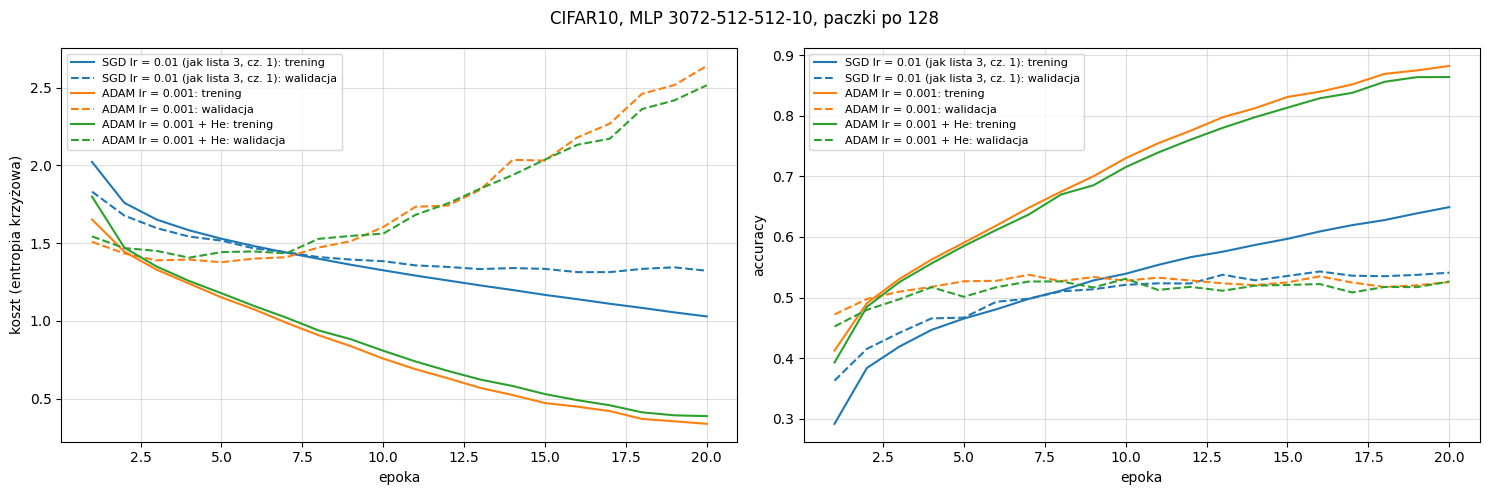

In [18]:
runs, rows = {}, []
for name in VARIANTS:
    model, h, acc, ep, sec = fit_cifar(name, seed=0)
    runs[name] = h
    rows.append({"wariant": name, "najlepsze accuracy walidacyjne": round(acc, 4), "najlepsza epoka": ep,
                 "min koszt walidacyjny": round(min(h["val_loss"]), 4), "epoka min kosztu": int(np.argmin(h["val_loss"])) + 1,
                 "accuracy treningowe na końcu": round(h["acc"][-1], 4), "czas [s]": round(sec)})
variants = pd.DataFrame(rows).set_index("wariant")
display(variants)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ep = np.arange(1, EPOCHS_C + 1)
for name, h in runs.items():
    line, = axes[0].plot(ep, h["loss"], label=f"{name}: trening")
    axes[0].plot(ep, h["val_loss"], ls="--", color=line.get_color(), label=f"{name}: walidacja")
    line, = axes[1].plot(ep, h["acc"], label=f"{name}: trening")
    axes[1].plot(ep, h["val_acc"], ls="--", color=line.get_color(), label=f"{name}: walidacja")
axes[0].set_ylabel("koszt (entropia krzyżowa)"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.set_xlabel("epoka"); ax.grid(alpha=0.4); ax.legend(fontsize=8)
fig.suptitle(f"CIFAR10, MLP 3072-512-512-10, paczki po {BS_C}")
fig.tight_layout()
plt.show()

- **Wniosek z listy 3 („ADAM lepszy”) nie przenosi się 1:1 na CIFAR10.**
  - **ADAM uczy się dużo szybciej:** accuracy walidacyjne 0.50 już po 2 epokach.
  - **ADAM szybko się przeucza:**
    - koszt walidacyjny ma minimum w 5. epoce, potem rośnie do ~2.6;
    - accuracy treningowe dochodzi do 88%, a walidacyjne stoi na ~0.52–0.54.
  - **SGD (lr = 0.01) uczy się wolniej, ale prawie się nie przeucza:** koszt walidacyjny spada do epoki ~16 i potem stoi na ~1.32.
    Po 20 epokach daje najlepsze accuracy walidacyjne (0.543 vs 0.538 ADAM).
- Różnica między wariantami jest mała (~1 punkt procentowy), ale SGD ma też wyraźnie najmniejszy koszt walidacyjny (1.31 vs 1.38 – 1.41).
- **Inicjalizacja He nic nie dała.** W liście 3 problemem była za mała inicjalizacja N(0, 0.01), przez którą sygnał zanikał.
  Domyślna inicjalizacja `nn.Linear` jest już dopasowana do liczby wejść, więc tego problemu tu nie ma.
- **Lista 3 vs CIFAR10:**
  - na małym zbiorze z listy 3 głównym problemem było **wyjście z plateau** i tu ADAM pomagał;
  - na CIFAR10 głównym problemem jest **przeuczenie**.

### Baseline: najlepszy wariant, 3 seedy, zbiór testowy

,najlepsza epoka,accuracy walidacyjne,accuracy testowe,koszt testowy
seed,,,,
0,16,0.5430,0.5297,1.3333
1,18,0.5460,0.5347,1.3217
2,19,0.5488,0.5361,1.3294


BASELINE (SGD lr = 0.01 (jak lista 3, cz. 1)): accuracy testowe 0.5335 ± 0.0027 (losowe zgadywanie 0.10)


,accuracy,najczęściej mylona z,ile razy
ship,0.662,airplane,109
frog,0.630,deer,88
automobile,0.625,truck,160
airplane,0.625,ship,122
horse,0.595,dog,85
truck,0.581,automobile,161
deer,0.426,bird,143
bird,0.421,deer,133
dog,0.415,cat,183
cat,0.317,dog,210


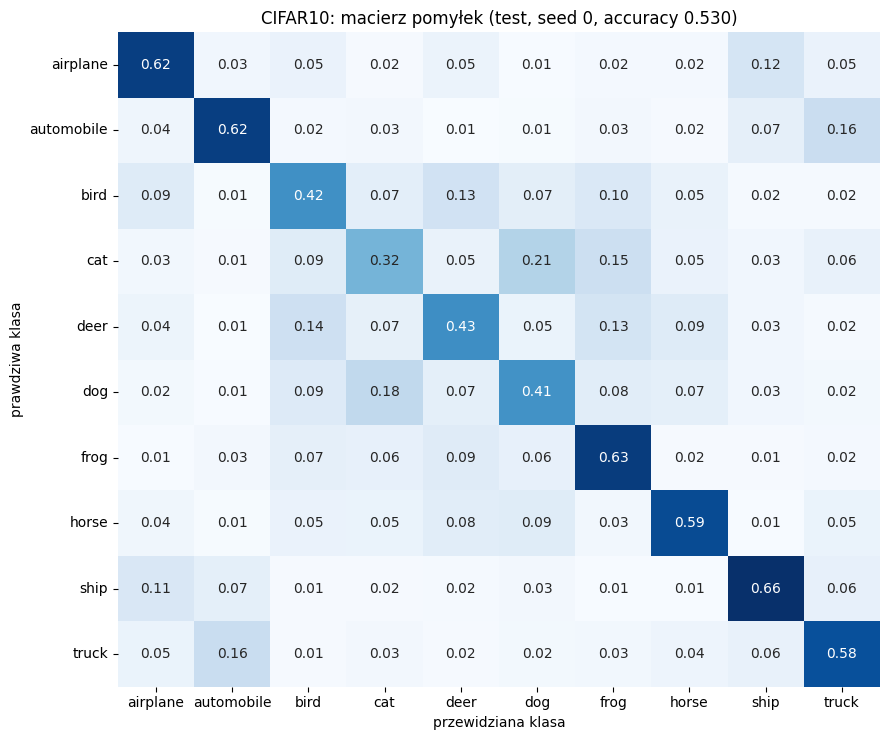

In [19]:
best_name = variants["najlepsze accuracy walidacyjne"].idxmax()
loss_fn = nn.CrossEntropyLoss()
rows, final = [], {}
for seed in [0, 1, 2]:
    model, h, acc, ep, sec = fit_cifar(best_name, seed=seed)
    tl, ta, preds = evaluate(test_loader, model, loss_fn)
    final[seed] = (model, preds)
    rows.append({"seed": seed, "najlepsza epoka": ep, "accuracy walidacyjne": round(acc, 4),
                 "accuracy testowe": round(ta, 4), "koszt testowy": round(tl, 4)})
base = pd.DataFrame(rows).set_index("seed")
display(base)
print(f"BASELINE ({best_name}): accuracy testowe {base['accuracy testowe'].mean():.4f} ± {base['accuracy testowe'].std(ddof=0):.4f} "
      f"(losowe zgadywanie 0.10)")
torch.save(final[0][0].state_dict(), "cifar10_mlp.pth")

cm = confusion_matrix(yc_test.numpy(), final[0][1].numpy())
off = cm.copy(); np.fill_diagonal(off, 0)
display(pd.DataFrame({"accuracy": (cm.diagonal() / cm.sum(axis=1)).round(3),
                      "najczęściej mylona z": [classes[i] for i in off.argmax(axis=1)],
                      "ile razy": off.max(axis=1)}, index=classes).sort_values("accuracy", ascending=False))

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=classes,
            yticklabels=classes, cbar=False, ax=ax)
ax.set_xlabel("przewidziana klasa"); ax.set_ylabel("prawdziwa klasa")
ax.set_title(f"CIFAR10: macierz pomyłek (test, seed 0, accuracy {base.loc[0, 'accuracy testowe']:.3f})")
fig.tight_layout()
plt.show()

## Wnioski – część 2

- **Baseline do kolejnego zadania:** MLP 3072-512-512-10 (sieć z tutorialu), SGD lr = 0.01, paczki po 128, 20 epok, model z najlepszej epoki na walidacji.
  **Accuracy testowe 0.5335 ± 0.0027** (3 seedy), losowe zgadywanie to 0.10. Wagi (seed 0) są w `cifar10_mlp.pth`.
- Wynik jest stabilny między seedami (0.530 – 0.536), a najlepsze epoki to 16–19 z 20. SGD przy dłuższym uczeniu mógłby jeszcze trochę zyskać.
- **Najlepiej rozpoznawane:** ship (0.66), frog, automobile i airplane (~0.63). **Najgorzej:** cat (0.32), dog, bird i deer (~0.42).
- **Pomyłki są sensowne:** zwykle w obrębie podobnych klas:
  - cat → dog 210 razy, dog → cat 183;
  - truck ↔ automobile 161 / 160;
  - deer ↔ bird 143 / 133;
  - airplane ↔ ship 122 / 109 (niebieskie tło: niebo i woda).
- **Główne ograniczenie:** `Flatten` zamienia obrazek w wektor 3072 liczb i sieć nie wie, które piksele są obok siebie. Ten sam kot przesunięty
  o kilka pikseli to dla niej zupełnie inne wejście. Na to powinny pomóc sieci, które przetwarzają obrazek z uwzględnieniem sąsiedztwa pikseli.
- Wszystko liczone na CPU (PyTorch bez CUDA, 8 wątków), ~40–60 s na jedno uczenie.